Step-1

In [ ]:
!pip install -q pypsa highspy

import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyPSA version:", pypsa.__version__)


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyPSA version: 1.4.0


In [ ]:

generators = pd.DataFrame({
    "unit": range(1, 13),
    "bus": [1, 2, 7, 13, 15, 15, 16, 18, 21, 22, 23, 23],
    "p_nom": [
        106.4, 106.4, 245, 413.7, 42, 108.5,
        108.5, 280, 280, 210, 217, 245
    ],
    "marginal_cost": [
        13.32, 13.32, 20.70, 20.93, 26.11, 10.52,
        10.52, 6.02, 5.47, 7.00, 10.52, 10.89
    ],
    "reserve_up_cost": [
        1.68, 1.68, 3.30, 4.07, 1.89, 5.48,
        5.48, 4.98, 5.53, 8.00, 3.45, 5.11
    ],
    "reserve_down_cost": [
        2.32, 2.32, 4.67, 3.93, 3.11, 3.52,
        3.52, 5.02, 4.97, 6.00, 2.52, 2.89
    ],
    "reserve_up_max": [
        48, 48, 84, 216, 42, 36,
        36, 60, 60, 48, 72, 48
    ],
    "reserve_down_max": [
        48, 48, 84, 216, 42, 36,
        36, 60, 60, 48, 72, 48
    ]
})

generators["name"] = "G" + generators["unit"].astype(str)

display(generators)
print("Installed conventional capacity:",
      generators.p_nom.sum(), "MW")


,unit,bus,p_nom,marginal_cost,reserve_up_cost,reserve_down_cost,reserve_up_max,reserve_down_max,name
0,1,1,106.4,13.32,1.68,2.32,48,48,G1
1,2,2,106.4,13.32,1.68,2.32,48,48,G2
2,3,7,245.0,20.70,3.30,4.67,84,84,G3
3,4,13,413.7,20.93,4.07,3.93,216,216,G4
4,5,15,42.0,26.11,1.89,3.11,42,42,G5
5,6,15,108.5,10.52,5.48,3.52,36,36,G6
6,7,16,108.5,10.52,5.48,3.52,36,36,G7
7,8,18,280.0,6.02,4.98,5.02,60,60,G8
8,9,21,280.0,5.47,5.53,4.97,60,60,G9
9,10,22,210.0,7.00,8.00,6.00,48,48,G10


Installed conventional capacity: 2362.5 MW


In [ ]:

wind_data = pd.DataFrame({
    "name": ["W1", "W2", "W3", "W4"],
    "bus": [3, 5, 16, 21],
    "p_nom": [500, 500, 300, 300],
    "forecast_mw": [120.54, 115.52, 53.34, 38.16]
})

wind_data["availability"] = (
    wind_data["forecast_mw"] / wind_data["p_nom"]
)

wind_data["marginal_cost"] = 0.0

load_data = pd.DataFrame({
    "bus": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
            13, 14, 15, 16, 18, 19, 20],
    "demand_mw": [
        84, 75, 139, 58, 55, 106, 97, 132, 135,
        150, 205, 150, 245, 77, 258, 141, 100
    ]
})

load_data["bid_price"] = 500.0

print("Conventional capacity:", generators.p_nom.sum(), "MW")
print("Wind forecast:", wind_data.forecast_mw.sum(), "MW")
print("Total demand:", load_data.demand_mw.sum(), "MW")

display(wind_data)
display(load_data)


Conventional capacity: 2362.5 MW
Wind forecast: 327.55999999999995 MW
Total demand: 2207 MW


,name,bus,p_nom,forecast_mw,availability,marginal_cost
0,W1,3,500,120.54,0.24108,0.0
1,W2,5,500,115.52,0.23104,0.0
2,W3,16,300,53.34,0.17780,0.0
3,W4,21,300,38.16,0.12720,0.0


,bus,demand_mw,bid_price
0,1,84,500.0
1,2,75,500.0
2,3,139,500.0
3,4,58,500.0
4,5,55,500.0
5,6,106,500.0
6,7,97,500.0
7,8,132,500.0
8,9,135,500.0
9,10,150,500.0


In [ ]:

n = pypsa.Network()

n.set_snapshots(pd.Index(["Hour_1"], name="snapshot"))
n.add("Bus", "Market")

# Conventional generators
for _, g in generators.iterrows():
    n.add(
        "Generator",
        g["name"],
        bus="Market",
        p_nom=float(g["p_nom"]),
        marginal_cost=float(g["marginal_cost"]),
        carrier="conventional"
    )

# Wind farms
for _, w in wind_data.iterrows():
    n.add(
        "Generator",
        w["name"],
        bus="Market",
        p_nom=float(w["p_nom"]),
        p_max_pu=float(w["availability"]),
        marginal_cost=0.0,
        carrier="wind"
    )

# Price-elastic demand
for _, d in load_data.iterrows():
    n.add(
        "Generator",
        f"D{int(d['bus'])}",
        bus="Market",
        sign=-1,
        p_nom=float(d["demand_mw"]),
        marginal_cost=-float(d["bid_price"]),
        carrier="demand"
    )

status, condition = n.optimize(solver_name="highs")

print("Solver:", status, condition)
assert status == "ok" and condition == "optimal"

market_price = float(
    n.buses_t.marginal_price.loc["Hour_1", "Market"]
)

dispatch = n.generators_t.p.loc["Hour_1"]

results = n.generators[
    ["carrier", "p_nom", "marginal_cost"]
].copy()

results["dispatch_mw"] = dispatch

supply = results[results.carrier != "demand"].copy()
demand = results[results.carrier == "demand"].copy()

supply["profit"] = (
    market_price - supply.marginal_cost
) * supply.dispatch_mw

demand["utility"] = (
    -demand.marginal_cost - market_price
) * demand.dispatch_mw

production_cost = (
    supply.marginal_cost * supply.dispatch_mw
).sum()

consumer_value = (
    -demand.marginal_cost * demand.dispatch_mw
).sum()

social_welfare = consumer_value - production_cost

print(f"\nMarket price: ${market_price:.2f}/MWh")
print(f"Generation: {supply.dispatch_mw.sum():.2f} MW")
print(f"Cleared demand: {demand.dispatch_mw.sum():.2f} MW")
print(f"Production cost: ${production_cost:,.2f}")
print(f"Social welfare: ${social_welfare:,.2f}")
print(f"Producer profits: ${supply.profit.sum():,.2f}")

assert np.isclose(
    supply.dispatch_mw.sum(),
    demand.dispatch_mw.sum(),
    atol=1e-5
)

display(supply.round(3))


/usr/local/lib/python3.13/dist-packages/pypsa/network/io.py:2079: FutureWarning:

pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.

/tmp/ipykernel_8591/3885553678.py:41: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['Market'], dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')


Solver: ok optimal

Market price: $20.70/MWh
Generation: 2207.00 MW
Cleared demand: 2207.00 MW
Production cost: $19,260.57
Social welfare: $1,084,239.43
Producer profits: $26,424.33


,carrier,p_nom,marginal_cost,dispatch_mw,profit
name,,,,,
G1,conventional,106.4,13.32,106.40,785.232
G2,conventional,106.4,13.32,106.40,785.232
G3,conventional,245.0,20.70,217.64,0.000
G4,conventional,413.7,20.93,-0.00,0.000
G5,conventional,42.0,26.11,-0.00,0.000
G6,conventional,108.5,10.52,108.50,1104.530
G7,conventional,108.5,10.52,108.50,1104.530
G8,conventional,280.0,6.02,280.00,4110.400
G9,conventional,280.0,5.47,280.00,4264.400


In [ ]:

n = pypsa.Network()
n.set_snapshots(pd.Index(["Hour_10"], name="snapshot"))

# One bus for the entire copper-plate market
n.add("Bus", "Market")

# Conventional generators
for _, g in generators.iterrows():
    n.add(
        "Generator",
        g["name"],
        bus="Market",
        p_nom=float(g["p_nom"]),
        marginal_cost=float(g["marginal_cost"]),
        carrier="conventional"
    )

# Wind generators
for _, w in wind_data.iterrows():
    n.add(
        "Generator",
        w["name"],
        bus="Market",
        p_nom=float(w["p_nom"]),
        p_max_pu=float(w["availability"]),
        marginal_cost=0.0,
        carrier="wind"
    )

# Price-elastic demand bids
for _, d in load_data.iterrows():
    n.add(
        "Generator",
        f"D{int(d['bus'])}",
        bus="Market",
        p_nom=float(d["demand_mw"]),
        marginal_cost=-float(d["bid_price"]),
        sign=-1,
        carrier="demand"
    )

print("Generators and demand bids added:",
      len(n.generators))

display(n.generators[[
    "bus", "p_nom", "marginal_cost", "sign"
]])


Generators and demand bids added: 33


,bus,p_nom,marginal_cost,sign
name,,,,
G1,Market,106.4,13.32,1.0
G2,Market,106.4,13.32,1.0
G3,Market,245.0,20.70,1.0
G4,Market,413.7,20.93,1.0
G5,Market,42.0,26.11,1.0
G6,Market,108.5,10.52,1.0
G7,Market,108.5,10.52,1.0
G8,Market,280.0,6.02,1.0
G9,Market,280.0,5.47,1.0


In [ ]:

dispatch = n.generators_t.p.loc["Hour_10"]

results = n.generators[[
    "carrier", "p_nom", "marginal_cost"
]].copy()

results["dispatch_mw"] = dispatch

supply = results[
    results["carrier"] != "demand"
].copy()

demand = results[
    results["carrier"] == "demand"
].copy()

supply["profit"] = (
    market_price - supply["marginal_cost"]
) * supply["dispatch_mw"]

demand["utility"] = (
    -demand["marginal_cost"] - market_price
) * demand["dispatch_mw"]

total_generation = supply["dispatch_mw"].sum()
total_consumption = demand["dispatch_mw"].sum()

production_cost = (
    supply["marginal_cost"] *
    supply["dispatch_mw"]
).sum()

consumer_value = (
    -demand["marginal_cost"] *
    demand["dispatch_mw"]
).sum()

social_welfare = consumer_value - production_cost

print(f"Price:              ${market_price:,.2f}/MWh")
print(f"Generation:         {total_generation:,.2f} MW")
print(f"Cleared demand:     {total_consumption:,.2f} MW")
print(f"Production cost:    ${production_cost:,.2f}")
print(f"Consumer value:     ${consumer_value:,.2f}")
print(f"Social welfare:     ${social_welfare:,.2f}")
print(f"Generator profits:  ${supply['profit'].sum():,.2f}")

assert np.isclose(
    total_generation,
    total_consumption,
    atol=1e-5
), "Power balance violated!"

print("\nGenerator dispatch and profits:")
display(supply.round(3))

print("\nDemand consumption and utilities:")
display(demand.round(3))


Price:              $20.70/MWh
Generation:         0.00 MW
Cleared demand:     0.00 MW
Production cost:    $0.00
Consumer value:     $0.00
Social welfare:     $0.00
Generator profits:  $0.00

Generator dispatch and profits:


,carrier,p_nom,marginal_cost,dispatch_mw,profit
name,,,,,
G1,conventional,106.4,13.32,NaN,NaN
G2,conventional,106.4,13.32,NaN,NaN
G3,conventional,245.0,20.70,NaN,NaN
G4,conventional,413.7,20.93,NaN,NaN
G5,conventional,42.0,26.11,NaN,NaN
G6,conventional,108.5,10.52,NaN,NaN
G7,conventional,108.5,10.52,NaN,NaN
G8,conventional,280.0,6.02,NaN,NaN
G9,conventional,280.0,5.47,NaN,NaN



Demand consumption and utilities:


,carrier,p_nom,marginal_cost,dispatch_mw,utility
name,,,,,
D1,demand,84.0,-500.0,NaN,NaN
D2,demand,75.0,-500.0,NaN,NaN
D3,demand,139.0,-500.0,NaN,NaN
D4,demand,58.0,-500.0,NaN,NaN
D5,demand,55.0,-500.0,NaN,NaN
D6,demand,106.0,-500.0,NaN,NaN
D7,demand,97.0,-500.0,NaN,NaN
D8,demand,132.0,-500.0,NaN,NaN
D9,demand,135.0,-500.0,NaN,NaN


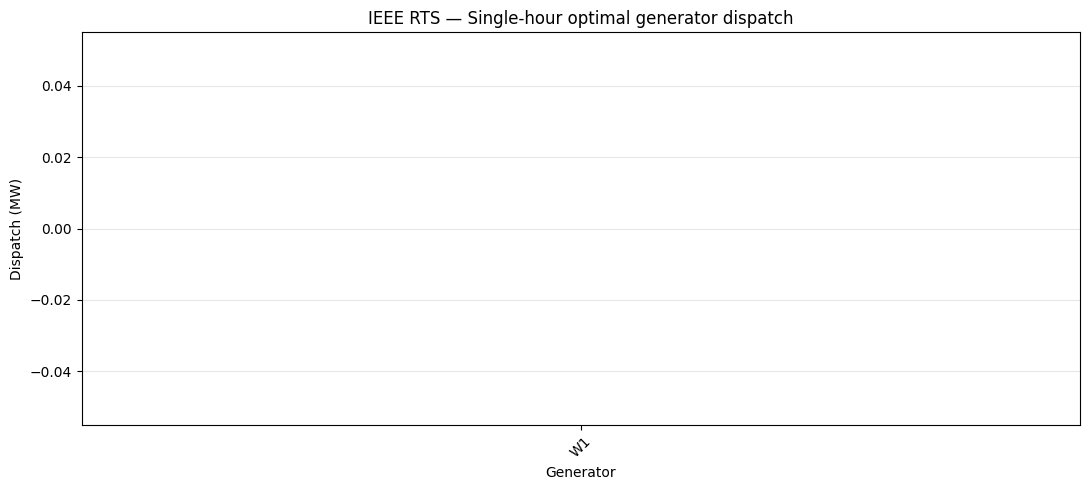

In [ ]:

plot_data = supply.sort_values(
    "marginal_cost"
)

plt.figure(figsize=(11, 5))

plt.bar(
    plot_data.index,
    plot_data["dispatch_mw"]
)

plt.xlabel("Generator")
plt.ylabel("Dispatch (MW)")
plt.title(
    "IEEE RTS — Single-hour optimal generator dispatch"
)

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Step-2

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

# IEEE RTS original 24-hour load shape
rts_demand = np.array([
    1775.835, 1669.815, 1590.300, 1563.795,
    1563.795, 1590.300, 1961.370, 2279.430,
    2517.975, 2544.480, 2544.480, 2517.975,
    2517.975, 2517.975, 2464.965, 2464.965,
    2623.995, 2650.500, 2650.500, 2544.480,
    2411.955, 2199.915, 1934.865, 1669.815
])

# Anchor the new dataset to hour 10 (index 9)
reference_hour = 9

reference_demand = load_data["demand_mw"].sum()

hourly_demand = (
    rts_demand / rts_demand[reference_hour]
    * reference_demand
)

# Illustrative wind profile, NOT actual forecast data
wind_shape = np.array([
    0.65, 0.70, 0.75, 0.72,
    0.68, 0.60, 0.55, 0.50,
    0.45, 0.40, 0.35, 0.30,
    0.32, 0.38, 0.45, 0.52,
    0.58, 0.62, 0.68, 0.72,
    0.78, 0.80, 0.75, 0.70
])

# 24-hour time index (illustrative date)
snapshots = pd.date_range(
    "2025-01-01",
    periods=24,
    freq="h"
)

demand_series = pd.Series(
    hourly_demand,
    index=snapshots
)

# Demand bids: higher during peak hours
hours = np.arange(1, 25)

demand_bid = pd.Series(
    np.where(
        (hours >= 8) & (hours <= 21),
        650.0,
        500.0
    ),
    index=snapshots
)

# Each farm's hour-10 forecast matches Table F.4
wind_forecasts = {}

for _, w in wind_data.iterrows():
    hourly_forecast = (
        float(w["forecast_mw"])
        * wind_shape / wind_shape[reference_hour]
    )

    hourly_forecast = np.clip(
        hourly_forecast,
        0,
        float(w["p_nom"])
    )

    wind_forecasts[w["name"]] = pd.Series(
        hourly_forecast,
        index=snapshots
    )

wind_forecasts = pd.DataFrame(wind_forecasts)

assert np.isclose(demand_series.iloc[9], 2207.0)

for _, w in wind_data.iterrows():
    assert np.isclose(
        wind_forecasts[w["name"]].iloc[9],
        w["forecast_mw"]
    )

print("Reference demand:", demand_series.iloc[9], "MW")
print("Peak demand:", demand_series.max(), "MW")
print("Hour-10 wind forecasts:")
display(wind_forecasts.iloc[[9]])

display(pd.DataFrame({
    "Demand_MW": demand_series,
    "Total_Wind_Forecast_MW": wind_forecasts.sum(axis=1),
    "Demand_Bid_USD_per_MWh": demand_bid
}).round(2))


Reference demand: 2207.0 MW
Peak demand: 2298.9583333333335 MW
Hour-10 wind forecasts:


,W1,W2,W3,W4
2025-01-01 09:00:00,120.54,115.52,53.34,38.16


,Demand_MW,Total_Wind_Forecast_MW,Demand_Bid_USD_per_MWh
2025-01-01 00:00:00,1540.30,532.28,500.0
2025-01-01 01:00:00,1448.34,573.23,500.0
2025-01-01 02:00:00,1379.38,614.17,500.0
2025-01-01 03:00:00,1356.39,589.61,500.0
2025-01-01 04:00:00,1356.39,556.85,500.0
2025-01-01 05:00:00,1379.38,491.34,500.0
2025-01-01 06:00:00,1701.23,450.40,500.0
2025-01-01 07:00:00,1977.10,409.45,650.0
2025-01-01 08:00:00,2184.01,368.50,650.0
2025-01-01 09:00:00,2207.00,327.56,650.0


In [ ]:

def build_market_24h(with_storage=False):

    network = pypsa.Network()
    network.set_snapshots(snapshots)
    network.add("Bus", "Market")

    # Conventional generators from Table F.4
    for _, g in generators.iterrows():
        network.add(
            "Generator",
            g["name"],
            bus="Market",
            p_nom=float(g["p_nom"]),
            marginal_cost=float(g["marginal_cost"]),
            carrier="conventional"
        )

    # Wind farms with time-varying forecasts
    for _, w in wind_data.iterrows():
        network.add(
            "Generator",
            w["name"],
            bus="Market",
            p_nom=float(w["p_nom"]),
            p_max_pu=(
                wind_forecasts[w["name"]]
                / float(w["p_nom"])
            ),
            marginal_cost=0.0,
            carrier="wind"
        )

    # Price-elastic demand bids
    # The base demand distribution is Table F.4
    for _, d in load_data.iterrows():

        hourly_bus_demand = (
            demand_series
            * float(d["demand_mw"])
            / reference_demand
        )

        network.add(
            "Generator",
            f"D{int(d['bus'])}",
            bus="Market",
            sign=-1,
            p_nom=float(hourly_bus_demand.max()),
            p_max_pu=(
                hourly_bus_demand
                / hourly_bus_demand.max()
            ),
            marginal_cost=-demand_bid,
            carrier="demand"
        )

    if with_storage:
        network.add(
            "StorageUnit",
            "Pumped_Storage",
            bus="Market",
            p_nom=300.0,
            max_hours=4.0,
            efficiency_store=0.90,
            efficiency_dispatch=0.95,
            marginal_cost=0.0,
            cyclic_state_of_charge=True,
            carrier="storage"
        )

    return network


n24_without = build_market_24h(False)
n24_with = build_market_24h(True)

print("Both market models constructed.")
print("Without storage:", len(n24_without.storage_units))
print("With storage:", len(n24_with.storage_units))


Both market models constructed.
Without storage: 0
With storage: 1


In [ ]:

for label, network in [
    ("Without storage", n24_without),
    ("With storage", n24_with)
]:

    status, condition = network.optimize(
        solver_name="highs"
    )

    print(label, ":", status, condition)

    assert status == "ok"
    assert condition == "optimal"

price_without = (
    n24_without.buses_t.marginal_price["Market"]
)

price_with = (
    n24_with.buses_t.marginal_price["Market"]
)

comparison = pd.DataFrame({
    "Hour": hours,
    "Demand_MW": demand_series.to_numpy(),
    "Price_Without": price_without.to_numpy(),
    "Price_With": price_with.to_numpy()
}, index=snapshots)

display(comparison.round(3))


/tmp/ipykernel_8591/3713611701.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['Market'], dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')
/tmp/ipykernel_8591/3713611701.py:6: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['Market'], dtype='object', name='n

Without storage : ok optimal
With storage : ok optimal


,Hour,Demand_MW,Price_Without,Price_With
2025-01-01 00:00:00,1,1540.302,10.52,10.52
2025-01-01 01:00:00,2,1448.344,10.52,10.52
2025-01-01 02:00:00,3,1379.375,7.00,10.52
2025-01-01 03:00:00,4,1356.385,7.00,10.52
2025-01-01 04:00:00,5,1356.385,10.52,10.52
2025-01-01 05:00:00,6,1379.375,10.52,10.52
2025-01-01 06:00:00,7,1701.229,10.89,10.89
2025-01-01 07:00:00,8,1977.104,13.32,13.32
2025-01-01 08:00:00,9,2184.010,20.70,20.70
2025-01-01 09:00:00,10,2207.000,20.70,20.70


In [ ]:

storage = n24_with.storage_units_t

storage_results = pd.DataFrame({
    "Charge_MW": storage.p_store["Pumped_Storage"],
    "Discharge_MW": storage.p_dispatch["Pumped_Storage"],
    "Energy_MWh": storage.state_of_charge["Pumped_Storage"],
    "Market_Price": price_with
})

storage_results["Net_Export_MW"] = (
    storage_results["Discharge_MW"]
    - storage_results["Charge_MW"]
)

# Hourly snapshots, each lasting one hour
storage_profit = (
    storage_results["Market_Price"]
    * storage_results["Net_Export_MW"]
).sum()

charge_energy = storage_results["Charge_MW"].sum()
discharge_energy = storage_results["Discharge_MW"].sum()

print(f"Storage profit: ${storage_profit:,.2f}")
print(f"Charging energy: {charge_energy:,.2f} MWh")
print(f"Discharging energy: {discharge_energy:,.2f} MWh")

if charge_energy > 1e-6:
    print(
        "Discharged / charged energy:",
        round(discharge_energy / charge_energy, 4)
    )

display(storage_results.round(3))

# Check for unintended simultaneous operation
simultaneous = (
    (storage_results["Charge_MW"] > 1e-5)
    & (storage_results["Discharge_MW"] > 1e-5)
)

print("Simultaneous charge/discharge hours:",
      simultaneous.sum())


Storage profit: $9,571.33
Charging energy: 1,333.33 MWh
Discharging energy: 1,140.00 MWh
Discharged / charged energy: 0.855


,Charge_MW,Discharge_MW,Energy_MWh,Market_Price,Net_Export_MW
snapshot,,,,,
2025-01-01 00:00:00,195.983,-0.000,176.385,10.52,-195.983
2025-01-01 01:00:00,-0.000,-0.000,176.385,10.52,0.000
2025-01-01 02:00:00,300.000,-0.000,446.385,10.52,-300.000
2025-01-01 03:00:00,237.350,-0.000,660.000,10.52,-237.350
2025-01-01 04:00:00,300.000,-0.000,930.000,10.52,-300.000
2025-01-01 05:00:00,300.000,-0.000,1200.000,10.52,-300.000
2025-01-01 06:00:00,-0.000,-0.000,1200.000,10.89,0.000
2025-01-01 07:00:00,-0.000,-0.000,1200.000,13.32,0.000
2025-01-01 08:00:00,-0.000,153.705,1038.205,20.70,153.705


Simultaneous charge/discharge hours: 0


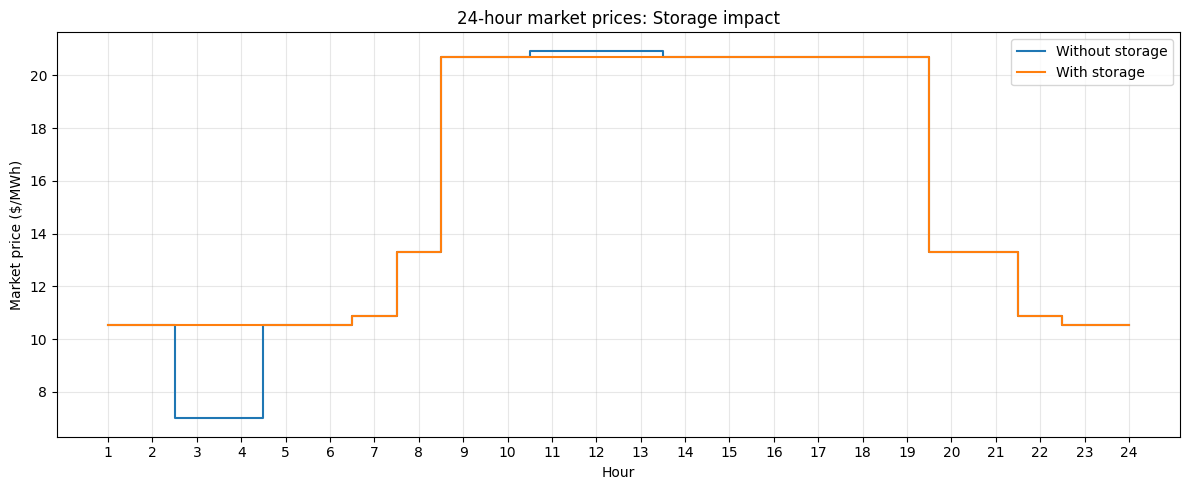

In [ ]:

plt.figure(figsize=(12, 5))

plt.step(
    hours,
    price_without.to_numpy(),
    where="mid",
    label="Without storage"
)

plt.step(
    hours,
    price_with.to_numpy(),
    where="mid",
    label="With storage"
)

plt.xlabel("Hour")
plt.ylabel("Market price ($/MWh)")
plt.title("24-hour market prices: Storage impact")
plt.xticks(hours)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


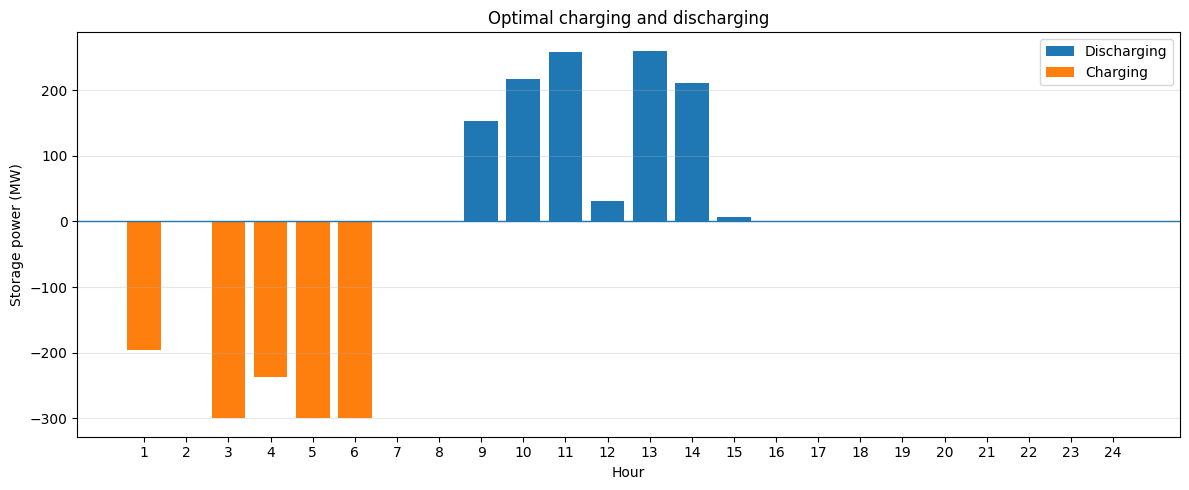

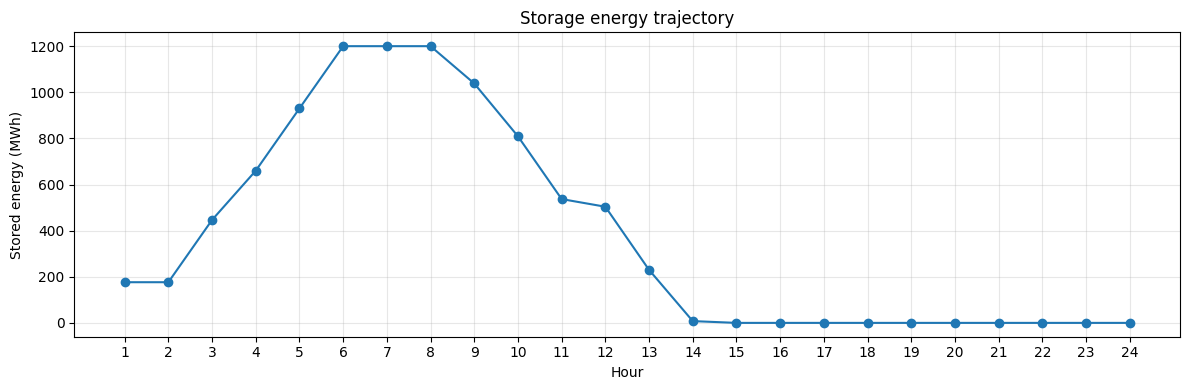

In [ ]:

plt.figure(figsize=(12, 5))

plt.bar(
    hours,
    storage_results["Discharge_MW"],
    label="Discharging"
)

plt.bar(
    hours,
    -storage_results["Charge_MW"],
    label="Charging"
)

plt.xlabel("Hour")
plt.ylabel("Storage power (MW)")
plt.title("Optimal charging and discharging")
plt.xticks(hours)
plt.axhline(0, linewidth=1)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))

plt.plot(
    hours,
    storage_results["Energy_MWh"],
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Stored energy (MWh)")
plt.title("Storage energy trajectory")
plt.xticks(hours)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

def analyze_market(network):

    p = network.generators_t.p
    meta = network.generators

    supply_names = meta.index[
        meta["carrier"].isin(["conventional", "wind"])
    ]

    demand_names = meta.index[
        meta["carrier"] == "demand"
    ]

    # Total production cost across 24 hours
    production_cost = (
        p[supply_names]
        * meta.loc[supply_names, "marginal_cost"]
    ).to_numpy().sum()

    # Consumer valuation: negative bid coefficients
    consumer_value = (
        p[demand_names]
        * (-network.generators_t.marginal_cost[
            demand_names
        ])
    ).to_numpy().sum()

    welfare = consumer_value - production_cost

    # Individual conventional/wind profits
    price = network.buses_t.marginal_price["Market"]

    profits = {}

    for name in supply_names:
        output = p[name]
        cost = meta.loc[name, "marginal_cost"]

        profits[name] = (
            output * (price - cost)
        ).sum()

    return {
        "production_cost": production_cost,
        "consumer_value": consumer_value,
        "welfare": welfare,
        "generator_profits": pd.Series(profits)
    }


base = analyze_market(n24_without)
with_storage = analyze_market(n24_with)

summary = pd.DataFrame({
    "Without storage": {
        "Production cost": base["production_cost"],
        "Consumer value": base["consumer_value"],
        "Social welfare": base["welfare"],
        "Generator profits": base["generator_profits"].sum(),
        "Storage profit": 0.0
    },
    "With storage": {
        "Production cost": with_storage["production_cost"],
        "Consumer value": with_storage["consumer_value"],
        "Social welfare": with_storage["welfare"],
        "Generator profits": with_storage["generator_profits"].sum(),
        "Storage profit": storage_profit
    }
})

summary["Difference"] = (
    summary["With storage"]
    - summary["Without storage"]
)

display(summary.round(2))

generator_comparison = pd.DataFrame({
    "Profit_Without": base["generator_profits"],
    "Profit_With": with_storage["generator_profits"]
})

generator_comparison["Difference"] = (
    generator_comparison["Profit_With"]
    - generator_comparison["Profit_Without"]
)

display(generator_comparison.round(2))


,Without storage,With storage,Difference
Production cost,307333.94,297720.50,-9613.44
Consumer value,27472552.08,27472552.08,0.00
Social welfare,27165218.15,27174831.59,9613.44
Generator profits,432355.22,440514.95,8159.73
Storage profit,0.00,9571.33,9571.33


,Profit_Without,Profit_With,Difference
G1,8710.97,8637.55,-73.42
G2,8710.97,8637.55,-73.42
G3,169.05,0.00,-169.05
G4,0.00,0.00,0.00
G5,0.00,0.00,0.00
G6,13216.38,13141.52,-74.86
G7,13216.38,13141.52,-74.86
G8,62375.60,64153.60,1778.00
G9,66071.60,67849.60,1778.00
G10,41842.50,43176.00,1333.50


In [ ]:

for label, network in [
    ("Without storage", n24_without),
    ("With storage", n24_with)
]:
    p = network.generators_t.p
    meta = network.generators

    supply = p.loc[:, meta.carrier.isin(
        ["conventional", "wind"]
    )].sum(axis=1)

    demand = p.loc[:, meta.carrier.eq(
        "demand"
    )].sum(axis=1)

    if len(network.storage_units):
        charging = network.storage_units_t.p_store.sum(axis=1)
        discharging = network.storage_units_t.p_dispatch.sum(axis=1)
    else:
        charging = pd.Series(0.0, index=snapshots)
        discharging = pd.Series(0.0, index=snapshots)

    residual = (
        supply + discharging - demand - charging
    )

    print(
        label,
        "maximum hourly balance error:",
        abs(residual).max(),
        "MW"
    )

    assert np.allclose(residual, 0, atol=1e-5)

print("All hourly power-balance checks passed.")


Without storage maximum hourly balance error: 6.821210263296962e-13 MW
With storage maximum hourly balance error: 6.821210263296962e-13 MW
All hourly power-balance checks passed.


In [ ]:
def audit_market(network):
    p = network.generators_t.p
    costs = network.generators.marginal_cost
    carriers = network.generators.carrier

    producers = carriers.index[
        carriers.isin(["conventional", "wind"])
    ]
    consumers = carriers.index[carriers.eq("demand")]

    dt = network.snapshot_weightings["objective"]

    # Production cost (positive value)
    production_cost = (
        p[producers]
        .mul(costs[producers])
        .sum(axis=1)
        .mul(dt)
        .sum()
    )

    # Consumer bids are stored dynamically in generators_t because they are time-varying in this model
    dynamic_costs = network.generators_t.marginal_cost

    # Consumer value (positive value)
    consumer_value = (
        -p[consumers]
        .mul(dynamic_costs[consumers])
        .sum(axis=1)
        .mul(dt)
        .sum()
    )

    price = network.buses_t.marginal_price["Market"]

    # Producer profit = market revenue - production cost
    producer_profit = (
        p[producers]
        .mul(
            price,
            axis=0
        )
        .sub(p[producers].mul(costs[producers]))
        .sum(axis=1)
        .mul(dt)
        .sum()
    )

    # Consumer surplus = gross consumer value - consumer payment
    # p is negative, so (-p * price) represents consumer payment (positive cash outflow from consumer perspective)
    consumer_surplus = (
        -p[consumers].mul(dynamic_costs[consumers]).sum(axis=1)
        .add(p[consumers].sum(axis=1) * price)
        .mul(dt)
        .sum()
    )

    storage_profit = 0.0

    if len(network.storage_units):
        storage_net = network.storage_units_t.p.sum(axis=1)
        storage_profit = (storage_net * price * dt).sum()

    welfare = consumer_value - production_cost
    welfare_from_surpluses = (
        consumer_surplus + producer_profit + storage_profit
    )

    return pd.Series({
        "Production cost": production_cost,
        "Consumer value": consumer_value,
        "Social welfare": welfare,
        "Consumer surplus": consumer_surplus,
        "Generator profits": producer_profit,
        "Storage profit": storage_profit,
        "Welfare from surpluses": welfare_from_surpluses,
        "Accounting residual": (
            welfare - welfare_from_surpluses
        )
    })


audit = pd.DataFrame({
    "Without storage": audit_market(n24_without),
    "With storage": audit_market(n24_with)
})

audit["Difference"] = (
    audit["With storage"] - audit["Without storage"]
)

display(audit.round(2))

assert np.allclose(
    audit.loc["Accounting residual"].values,
    0,
    atol=1e-4
)

print("Economic accounting reconciled successfully.")

,Without storage,With storage,Difference
Production cost,307333.94,297720.50,-9613.44
Consumer value,27472552.08,27472552.08,0.00
Social welfare,27165218.15,27174831.59,9613.44
Consumer surplus,26732862.93,26724745.31,-8117.62
Generator profits,432355.22,440514.95,8159.73
Storage profit,0.00,9571.33,9571.33
Welfare from surpluses,27165218.15,27174831.59,9613.44
Accounting residual,0.00,0.00,0.00


Economic accounting reconciled successfully.


In [ ]:

# Step 2 — Storage physics validation

su = n24_with.storage_units.loc["Pumped_Storage"]
p_ch = n24_with.storage_units_t.p_store["Pumped_Storage"]
p_dis = n24_with.storage_units_t.p_dispatch["Pumped_Storage"]
e = n24_with.storage_units_t.state_of_charge["Pumped_Storage"]

dt = 1.0  # One-hour snapshots
eta_ch = su.efficiency_store
eta_dis = su.efficiency_dispatch

# Cyclic condition: previous energy for first hour is last-hour energy
e_previous = e.shift(1)
e_previous.iloc[0] = e.iloc[-1]

e_expected = (
    e_previous
    + eta_ch * p_ch * dt
    - p_dis * dt / eta_dis
)

residual = e - e_expected

print("Maximum storage balance error:",
      residual.abs().max(), "MWh")

print("Maximum stored energy:", e.max(), "MWh")
print("Minimum stored energy:", e.min(), "MWh")

print("Simultaneous operation hours:",
      ((p_ch > 1e-6) & (p_dis > 1e-6)).sum())

assert residual.abs().max() < 1e-4
assert e.min() >= -1e-4
assert e.max() <= 1200 + 1e-4

print("Storage physics validated.")


Maximum storage balance error: 8.881784197001252e-16 MWh
Maximum stored energy: 1200.0 MWh
Minimum stored energy: -0.0 MWh
Simultaneous operation hours: 0
Storage physics validated.


With Actual Forecast Data

In [ ]:
import io
import zipfile
import numpy as np
import pandas as pd
from google.colab import files

uploaded = files.upload()

# Find the uploaded zip file name dynamically (handles renames like 'data (1).zip')
zip_name = next((k for k in uploaded.keys() if k.endswith(".zip")), "data.zip")

zone_profiles = {}

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    for zone in range(1, 16):
        filename = f"data/scen_zone{zone}.out"

        df = pd.read_csv(
            io.BytesIO(archive.read(filename)),
            index_col=0
        )

        # Remove the non-numeric END row
        df = df.drop(index="END", errors="ignore")
        df = df.apply(pd.to_numeric, errors="raise")
        df.index = df.index.astype(int)

        assert df.shape == (43, 100)
        assert df.notna().all().all()
        assert ((df >= 0) & (df <= 1)).all().all()

        zone_profiles[zone] = df

print("Loaded", len(zone_profiles), "wind zones")
print("Shape of each zone:", zone_profiles[1].shape)

display(zone_profiles[1].iloc[:10, :5])

Saving data.zip to data.zip
Loaded 15 wind zones
Shape of each zone: (43, 100)


,V1,V2,V3,V4,V5
1,0.384460,0.507700,0.464001,0.476854,0.480010
2,0.334138,0.454995,0.545837,0.539686,0.518081
3,0.392110,0.584795,0.714401,0.673901,0.641382
4,0.320718,0.671243,0.797851,0.668318,0.714843
5,0.511098,0.727537,0.804719,0.826516,0.720152
6,0.670195,0.655562,0.785114,0.809138,0.723181
7,0.732583,0.768349,0.707830,0.799635,0.764298
8,0.715879,0.816962,0.776470,0.854024,0.793214
9,0.816484,0.722401,0.863191,0.926590,0.754504
10,0.863173,0.520111,0.833182,0.890072,0.748322


In [ ]:

# Provisional mapping, not a verified geographical mapping
wind_zone_mapping = {
    "W1": 1,
    "W2": 2,
    "W3": 3,
    "W4": 4
}

scenario = "V1"
reference_hour = 9  # zero-based index: hour 10

wind_forecasts_sourced = pd.DataFrame(
    index=snapshots
)

for _, w in wind_data.iterrows():

    name = w["name"]
    zone = wind_zone_mapping[name]

    # First 24 data periods of the same scenario
    profile = zone_profiles[zone][scenario].iloc[:24].to_numpy()

    reference_value = profile[reference_hour]

    if reference_value <= 0:
        raise ValueError(
            f"Cannot anchor {name}: zero reference value"
        )

    # Preserve Table F.4's hour-10 wind forecast
    forecast = (
        float(w["forecast_mw"])
        * profile / reference_value
    )

    # Respect installed generator capacity
    forecast = np.clip(
        forecast, 0, float(w["p_nom"])
    )

    wind_forecasts_sourced[name] = forecast

assert np.allclose(
    wind_forecasts_sourced.iloc[reference_hour].to_numpy(),
    wind_data["forecast_mw"].to_numpy()
)

display(wind_forecasts_sourced.round(3))

print("Hour-10 total wind forecast:",
      wind_forecasts_sourced.iloc[9].sum(), "MW")


,W1,W2,W3,W4
2025-01-01 00:00:00,53.689,99.218,28.391,10.557
2025-01-01 01:00:00,46.662,97.994,41.334,16.418
2025-01-01 02:00:00,54.757,109.202,41.777,22.587
2025-01-01 03:00:00,44.788,99.663,48.477,23.623
2025-01-01 04:00:00,71.374,116.757,53.721,30.550
2025-01-01 05:00:00,93.591,118.357,55.570,28.478
2025-01-01 06:00:00,102.303,120.383,56.418,32.796
2025-01-01 07:00:00,99.971,121.638,55.633,31.802
2025-01-01 08:00:00,114.020,124.371,55.943,36.417
2025-01-01 09:00:00,120.540,115.520,53.340,38.160


Hour-10 total wind forecast: 327.55999999999995 MW


In [ ]:
# Preserve the earlier synthetic forecasts
wind_forecasts_synthetic = wind_forecasts.copy()

# Switch the input used by build_market_24h()
wind_forecasts = wind_forecasts_sourced.copy()

# Build fresh networks
n24_without_sourced = build_market_24h(False)
n24_with_sourced = build_market_24h(True)

for network in [n24_without_sourced, n24_with_sourced]:
    status, condition = network.optimize(solver_name="highs")
    assert status == "ok" and condition == "optimal"

/tmp/ipykernel_8591/1810219772.py:12: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['Market'], dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')
/tmp/ipykernel_8591/1810219772.py:12: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['Market'], dtype='object', name=

Step-3 (Nodal)

In [ ]:
line_data = pd.DataFrame({
    "from_bus": [
        1,1,1,2,2,3,3,4,5,6,7,8,8,9,9,10,10,
        11,11,12,12,13,14,15,15,15,16,16,
        17,17,18,19,20,21
    ],
    "to_bus": [
        2,3,5,4,6,9,24,9,10,10,8,9,10,11,12,11,12,
        13,14,13,23,23,16,16,21,24,17,19,
        18,22,21,20,23,22
    ],
    "x_pu": [
        0.0146,0.2253,0.0907,0.1356,0.2050,
        0.1271,0.0840,0.1110,0.0940,0.0642,
        0.0652,0.1762,0.1762,0.0840,0.0840,
        0.0840,0.0840,
        0.0488,0.0426,0.0488,0.0985,
        0.0884,0.0594,0.0172,0.0249,
        0.0529,0.0263,0.0234,0.0143,
        0.1069,0.0132,0.0203,0.0112,0.0692
    ],
    "capacity_mw": [
        175,175,350,175,175,175,400,175,350,
        175,350,175,175,400,400,400,400,
        500,500,500,500,250,250,500,400,
        500,500,500,500,500,1000,1000,
        1000,500
    ]
})

line_data["name"] = [
    f"L{a}-{b}"
    for a, b in zip(
        line_data["from_bus"],
        line_data["to_bus"]
    )
]

assert len(line_data) == 34
assert (line_data["x_pu"] > 0).all()
assert (line_data["capacity_mw"] > 0).all()
assert not line_data["name"].duplicated().any()

display(line_data)
print("Transmission lines:", len(line_data))


,from_bus,to_bus,x_pu,capacity_mw,name
0,1,2,0.0146,175,L1-2
1,1,3,0.2253,175,L1-3
2,1,5,0.0907,350,L1-5
3,2,4,0.1356,175,L2-4
4,2,6,0.2050,175,L2-6
5,3,9,0.1271,175,L3-9
6,3,24,0.0840,400,L3-24
7,4,9,0.1110,175,L4-9
8,5,10,0.0940,350,L5-10
9,6,10,0.0642,175,L6-10


Transmission lines: 34


In [ ]:
def build_nodal_market(line_limits=None):

    network = pypsa.Network()
    network.set_snapshots(
        pd.Index(["Hour_1"], name="snapshot")
    )

    S_BASE = 100.0  # MVA
    V_BASE = 100.0  # kV; common modelling base

    # Create 24 buses
    for bus in range(1, 25):
        network.add(
            "Bus",
            f"Bus_{bus}",
            v_nom=V_BASE,
            carrier="AC"
        )

    # Add transmission lines
    for _, line in line_data.iterrows():

        x_ohm = (
            float(line["x_pu"])
            * V_BASE**2
            / S_BASE
        )

        rating = float(line["capacity_mw"])

        if line_limits is not None:
            rating = float(
                line_limits.get(line["name"], rating)
            )

        network.add(
            "Line",
            line["name"],
            bus0=f"Bus_{int(line['from_bus'])}",
            bus1=f"Bus_{int(line['to_bus'])}",
            x=x_ohm,
            r=0.0,
            s_nom=rating,
            s_max_pu=1.0
        )

    # Conventional generators
    for _, g in generators.iterrows():
        network.add(
            "Generator",
            g["name"],
            bus=f"Bus_{int(g['bus'])}",
            p_nom=float(g["p_nom"]),
            marginal_cost=float(g["marginal_cost"]),
            carrier="conventional"
        )

    # Four wind farms: Table F.4
    for _, w in wind_data.iterrows():
        network.add(
            "Generator",
            w["name"],
            bus=f"Bus_{int(w['bus'])}",
            p_nom=float(w["p_nom"]),
            p_max_pu=float(w["availability"]),
            marginal_cost=0.0,
            carrier="wind"
        )

    # Price-elastic demand
    for _, d in load_data.iterrows():
        network.add(
            "Generator",
            f"D{int(d['bus'])}",
            bus=f"Bus_{int(d['bus'])}",
            sign=-1,
            p_nom=float(d["demand_mw"]),
            marginal_cost=-float(d["bid_price"]),
            carrier="demand"
        )

    return network


n_nodal = build_nodal_market()

print("Buses:", len(n_nodal.buses))
print("Lines:", len(n_nodal.lines))
print("Generators and demand bids:",
      len(n_nodal.generators))

display(n_nodal.buses.head())
display(n_nodal.lines.head())


Buses: 24
Lines: 34
Generators and demand bids: 33


,v_nom,type,x,y,carrier,unit,location,v_mag_pu_set,v_mag_pu_min,v_mag_pu_max,control,generator,sub_network
name,,,,,,,,,,,,,
Bus_1,100.0,,0.0,0.0,AC,,,1.0,0.0,inf,PQ,,
Bus_2,100.0,,0.0,0.0,AC,,,1.0,0.0,inf,PQ,,
Bus_3,100.0,,0.0,0.0,AC,,,1.0,0.0,inf,PQ,,
Bus_4,100.0,,0.0,0.0,AC,,,1.0,0.0,inf,PQ,,
Bus_5,100.0,,0.0,0.0,AC,,,1.0,0.0,inf,PQ,,


,bus0,bus1,type,x,r,g,b,s_nom,s_nom_mod,s_nom_extendable,...,v_ang_max,sub_network,x_pu,r_pu,g_pu,b_pu,x_pu_eff,r_pu_eff,s_nom_opt,capital_cost_piecewise_opt
name,,,,,,,,,,,,,,,,,,,,,
L1-2,Bus_1,Bus_2,,1.46,0.0,0.0,0.0,175.0,0.0,False,...,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
L1-3,Bus_1,Bus_3,,22.53,0.0,0.0,0.0,175.0,0.0,False,...,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
L1-5,Bus_1,Bus_5,,9.07,0.0,0.0,0.0,350.0,0.0,False,...,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
L2-4,Bus_2,Bus_4,,13.56,0.0,0.0,0.0,175.0,0.0,False,...,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
L2-6,Bus_2,Bus_6,,20.50,0.0,0.0,0.0,175.0,0.0,False,...,inf,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
status, condition = n_nodal.optimize(
    solver_name="highs"
)

print("Solver status:", status)
print("Termination:", condition)

assert status == "ok" and condition == "optimal"

nodal_prices = (
    n_nodal.buses_t.marginal_price.loc["Hour_1"]
)

print("\nNodal market-clearing prices:")
display(
    nodal_prices.rename("LMP_USD_per_MWh")
    .to_frame()
    .round(3)
)

print("\nMinimum LMP:", nodal_prices.min())
print("Maximum LMP:", nodal_prices.max())
print("LMP spread:", nodal_prices.max() - nodal_prices.min())


/tmp/ipykernel_8591/265005807.py:1: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['Bus_1', 'Bus_2', 'Bus_3', 'Bus_4', 'Bus_5', 'Bus_6', 'Bus_7', 'Bus_8',
       'Bus_9', 'Bus_10', 'Bus_11', 'Bus_12', 'Bus_13', 'Bus_14', 'Bus_15',
       'Bus_16', 'Bus_17', 'Bus_18', 'Bus_19', 'Bus_20', 'Bus_21', 'Bus_22',
       'Bus_23', 'Bus_24'],
      dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')
Index(['L1-2', 'L1-3', 'L1-5', 'L2-4', 'L2-6', 'L3-9', 'L3-24', 'L4-9',
       'L5-10', 'L6-10', 'L7-8', 'L8-9', 'L8-

Solver status: ok
Termination: optimal

Nodal market-clearing prices:


,LMP_USD_per_MWh
name,
Bus_1,19.766
Bus_2,19.859
Bus_3,16.782
Bus_4,20.143
Bus_5,20.384
Bus_6,20.747
Bus_7,20.700
Bus_8,20.700
Bus_9,20.374



Minimum LMP: 10.52
Maximum LMP: 29.275587691057957
LMP spread: 18.755587691057958


In [ ]:

flows = n_nodal.lines_t.p0.loc["Hour_1"]

line_results = n_nodal.lines[
    ["bus0", "bus1", "s_nom"]
].copy()

line_results["Flow_MW"] = flows

line_results["Loading_pct"] = (
    flows.abs() / line_results["s_nom"] * 100
)

line_results["Remaining_MW"] = (
    line_results["s_nom"] - flows.abs()
)

line_results["At_limit"] = (
    line_results["Remaining_MW"].abs() < 1e-4
)

line_results = line_results.sort_values(
    "Loading_pct",
    ascending=False
)

display(line_results.round(3))

print(
    "\nLines at capacity:",
    line_results["At_limit"].sum()
)


,bus0,bus1,s_nom,Flow_MW,Loading_pct,Remaining_MW,At_limit
name,,,,,,,
L14-16,Bus_14,Bus_16,250.0,-250.000,100.000,0.000,True
L15-21,Bus_15,Bus_21,400.0,-321.006,80.252,78.994,False
L13-23,Bus_13,Bus_23,250.0,-192.064,76.826,57.936,False
L16-17,Bus_16,Bus_17,500.0,-229.154,45.831,270.846,False
L3-9,Bus_3,Bus_9,175.0,68.091,38.909,106.909,False
L6-10,Bus_6,Bus_10,175.0,-63.104,36.059,111.896,False
L7-8,Bus_7,Bus_8,350.0,125.366,35.819,224.634,False
L12-23,Bus_12,Bus_23,500.0,-162.056,32.411,337.944,False
L3-24,Bus_3,Bus_24,400.0,-110.654,27.663,289.346,False



Lines at capacity: 1


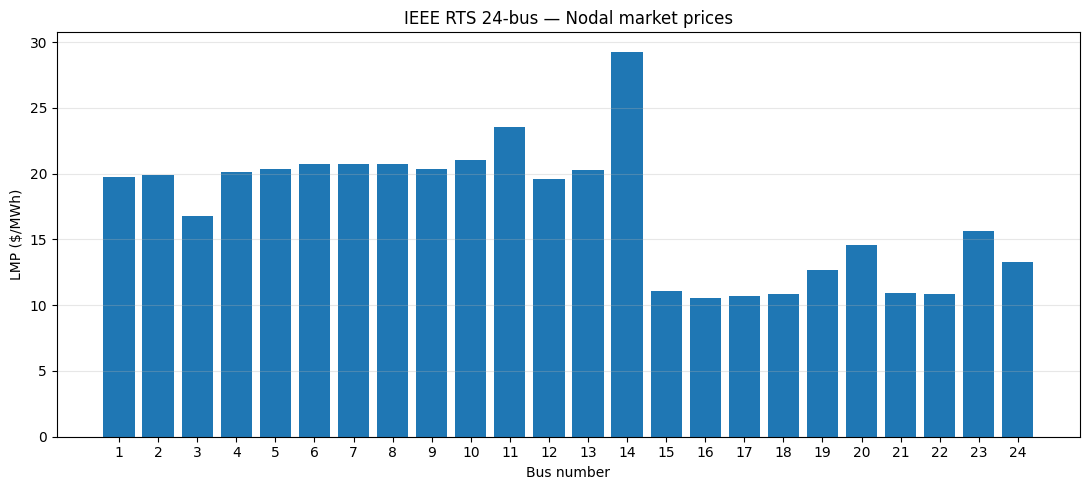

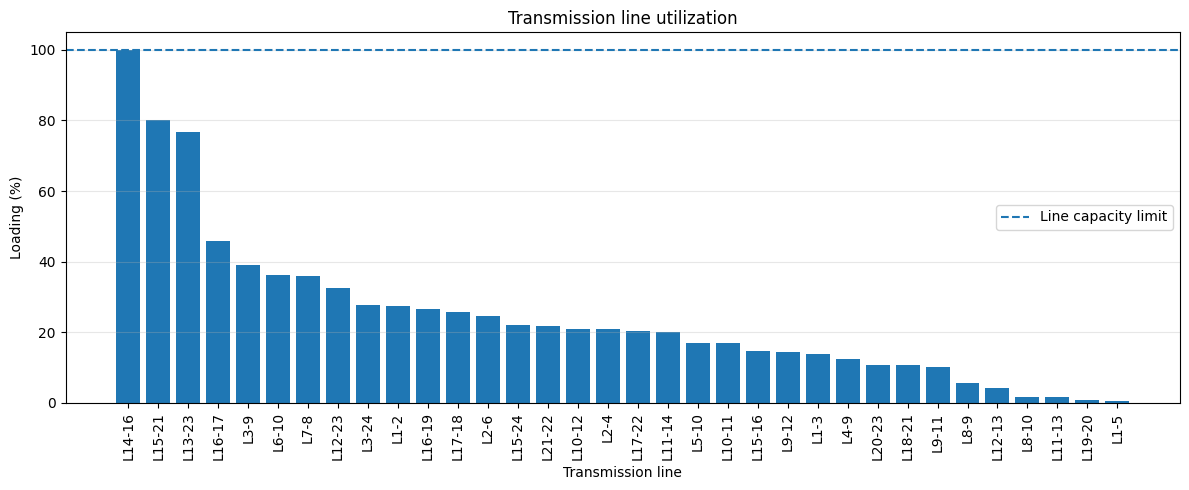

In [ ]:

bus_numbers = [
    int(b.split("_")[1])
    for b in nodal_prices.index
]

price_plot = pd.DataFrame({
    "Bus": bus_numbers,
    "LMP": nodal_prices.values
}).sort_values("Bus")

plt.figure(figsize=(11, 5))

plt.bar(
    price_plot["Bus"],
    price_plot["LMP"]
)

plt.xlabel("Bus number")
plt.ylabel("LMP ($/MWh)")
plt.title("IEEE RTS 24-bus — Nodal market prices")
plt.xticks(range(1, 25))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))

plt.bar(
    line_results.index,
    line_results["Loading_pct"]
)

plt.axhline(
    100,
    linestyle="--",
    label="Line capacity limit"
)

plt.xlabel("Transmission line")
plt.ylabel("Loading (%)")
plt.title("Transmission line utilization")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

p = n_nodal.generators_t.p.loc["Hour_1"]
meta = n_nodal.generators

producer_names = meta.index[
    meta.carrier.isin(["conventional", "wind"])
]

consumer_names = meta.index[
    meta.carrier == "demand"
]

nodal_production_cost = (
    p[producer_names]
    * meta.loc[producer_names, "marginal_cost"]
).sum()

nodal_consumer_value = (
    p[consumer_names]
    * -meta.loc[consumer_names, "marginal_cost"]
).sum()

nodal_welfare = (
    nodal_consumer_value - nodal_production_cost
)

nodal_dispatch = pd.DataFrame({
    "Bus": meta.loc[producer_names, "bus"],
    "Dispatch_MW": p[producer_names],
    "Cost_USD_per_MWh":
        meta.loc[producer_names, "marginal_cost"]
})

print("Nodal production cost:",
      round(nodal_production_cost, 2))

print("Nodal consumer value:",
      round(nodal_consumer_value, 2))

print("Nodal social welfare:",
      round(nodal_welfare, 2))

print("Copper-plate welfare: 1,084,239.43 USD")
print("Copper-plate price: 20.70 USD/MWh")

display(nodal_dispatch.round(3))

assert nodal_welfare <= 1084239.43 + 0.05, (
    "Nodal welfare exceeds copper-plate welfare. "
    "Check consistency of input data."
)

# Check total cleared supply and demand
total_supply = p[producer_names].sum()
total_demand = p[consumer_names].sum()

print("Total supply:", total_supply, "MW")
print("Total cleared demand:", total_demand, "MW")
print("Power balance residual:",
      total_supply - total_demand, "MW")

assert np.isclose(
    total_supply, total_demand, atol=1e-5
)


Nodal production cost: 19308.69
Nodal consumer value: 1103500.0
Nodal social welfare: 1084191.31
Copper-plate welfare: 1,084,239.43 USD
Copper-plate price: 20.70 USD/MWh


,Bus,Dispatch_MW,Cost_USD_per_MWh
name,,,
G1,Bus_1,106.400,13.32
G2,Bus_2,106.400,13.32
G3,Bus_7,222.366,20.70
G4,Bus_13,-0.000,20.93
G5,Bus_15,-0.000,26.11
G6,Bus_15,108.500,10.52
G7,Bus_16,103.774,10.52
G8,Bus_18,280.000,6.02
G9,Bus_21,280.000,5.47


Total supply: 2207.0 MW
Total cleared demand: 2207.0 MW
Power balance residual: 0.0 MW


In [ ]:

# Re-solve while explicitly assigning constraint duals
status, condition = n_nodal.optimize(
    solver_name="highs",
    assign_all_duals=True,
    include_objective_constant=False
)

assert status == "ok" and condition == "optimal"

print("Solver:", status, condition)

# Check the congested line
line = "L14-16"
snapshot = n_nodal.snapshots[0]

flow = n_nodal.lines_t.p0.loc[snapshot, line]
limit = n_nodal.lines.loc[line, "s_nom"]

print(f"\nLine: {line}")
print(f"Flow: {flow:.4f} MW")
print(f"Capacity: +/-{limit:.4f} MW")

# Access line constraint dual variables
for attribute in ["mu_lower", "mu_upper"]:
    values = getattr(n_nodal.lines_t, attribute, None)

    if values is not None and line in values.columns:
        print(
            f"{attribute}:",
            values.loc[snapshot, line]
        )
    else:
        print(attribute, "not available")

# Report endpoint LMPs
lmp = n_nodal.buses_t.marginal_price.loc[snapshot]

print(f"\nLMP Bus 14: ${lmp['Bus_14']:.4f}/MWh")
print(f"LMP Bus 16: ${lmp['Bus_16']:.4f}/MWh")

print(
    "Endpoint price spread:",
    round(lmp["Bus_14"] - lmp["Bus_16"], 4),
    "$/MWh"
)


Index(['Bus_1', 'Bus_2', 'Bus_3', 'Bus_4', 'Bus_5', 'Bus_6', 'Bus_7', 'Bus_8',
       'Bus_9', 'Bus_10', 'Bus_11', 'Bus_12', 'Bus_13', 'Bus_14', 'Bus_15',
       'Bus_16', 'Bus_17', 'Bus_18', 'Bus_19', 'Bus_20', 'Bus_21', 'Bus_22',
       'Bus_23', 'Bus_24'],
      dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')
Index(['L1-2', 'L1-3', 'L1-5', 'L2-4', 'L2-6', 'L3-9', 'L3-24', 'L4-9',
       'L5-10', 'L6-10', 'L7-8', 'L8-9', 'L8-10', 'L9-11', 'L9-12', 'L10-11',
       'L10-12', 'L11-13', 'L11-14', 'L12-13', 'L12-23', 'L13-23', 'L14-16',
       'L15-16', 'L15-21', 'L15-24', 'L16-17', 'L16-19', 'L17-18', 'L17-22',
       'L18-21', 'L19-20', 'L20-23', 'L21-22'],
      dtype='object', name='name')
Index(['L1-2', 'L1-3', 'L1-5', 'L2-4', 'L2-6', 'L3-9

Solver: ok optimal

Line: L14-16
Flow: -250.0000 MW
Capacity: +/-250.0000 MW
mu_lower: 26.746276897003447
mu_upper: -0.0

LMP Bus 14: $29.2756/MWh
LMP Bus 16: $10.5200/MWh
Endpoint price spread: 18.7556 $/MWh


In [ ]:

capacities = [150, 200, 250, 251, 300, 400]

sensitivity_results = []
sensitivity_networks = {}

for capacity in capacities:

    network = build_nodal_market(
        line_limits={"L14-16": capacity}
    )

    network.sanitize()

    status, condition = network.optimize(
        solver_name="highs",
        assign_all_duals=True,
        include_objective_constant=False
    )

    assert status == "ok" and condition == "optimal"

    snapshot = network.snapshots[0]

    prices = network.buses_t.marginal_price.loc[snapshot]
    dispatch = network.generators_t.p.loc[snapshot]
    meta = network.generators

    producers = meta.index[
        meta.carrier.isin(["conventional", "wind"])
    ]

    consumers = meta.index[
        meta.carrier == "demand"
    ]

    production_cost = (
        dispatch[producers]
        * meta.loc[producers, "marginal_cost"]
    ).sum()

    consumer_value = (
        dispatch[consumers]
        * -meta.loc[consumers, "marginal_cost"]
    ).sum()

    welfare = consumer_value - production_cost

    flow = network.lines_t.p0.loc[
        snapshot, "L14-16"
    ]

    mu_lower = network.lines_t.mu_lower.loc[
        snapshot, "L14-16"
    ]

    mu_upper = network.lines_t.mu_upper.loc[
        snapshot, "L14-16"
    ]

    sensitivity_results.append({
        "Capacity_MW": capacity,
        "Flow_MW": flow,
        "Loading_pct": abs(flow) / capacity * 100,
        "LMP_Bus14": prices["Bus_14"],
        "LMP_Bus16": prices["Bus_16"],
        "LMP_Spread": prices.max() - prices.min(),
        "Line_Shadow_Value": mu_lower + mu_upper,
        "Production_Cost": production_cost,
        "Consumer_Value": consumer_value,
        "Social_Welfare": welfare
    })

    sensitivity_networks[capacity] = network

sensitivity_df = pd.DataFrame(
    sensitivity_results
).set_index("Capacity_MW")

display(sensitivity_df.round(3))


Index(['L1-2', 'L1-3', 'L1-5', 'L2-4', 'L2-6', 'L3-9', 'L3-24', 'L4-9',
       'L5-10', 'L6-10', 'L7-8', 'L8-9', 'L8-10', 'L9-11', 'L9-12', 'L10-11',
       'L10-12', 'L11-13', 'L11-14', 'L12-13', 'L12-23', 'L13-23', 'L14-16',
       'L15-16', 'L15-21', 'L15-24', 'L16-17', 'L16-19', 'L17-18', 'L17-22',
       'L18-21', 'L19-20', 'L20-23', 'L21-22'],
      dtype='object', name='name')
Index(['L1-2', 'L1-3', 'L1-5', 'L2-4', 'L2-6', 'L3-9', 'L3-24', 'L4-9',
       'L5-10', 'L6-10', 'L7-8', 'L8-9', 'L8-10', 'L9-11', 'L9-12', 'L10-11',
       'L10-12', 'L11-13', 'L11-14', 'L12-13', 'L12-23', 'L13-23', 'L14-16',
       'L15-16', 'L15-21', 'L15-24', 'L16-17', 'L16-19', 'L17-18', 'L17-22',
       'L18-21', 'L19-20', 'L20-23', 'L21-22'],
      dtype='object', name='name')
Index(['L1-2', 'L1-3', 'L1-5', 'L2-4', 'L2-6', 'L3-9', 'L3-24', 'L4-9',
       'L5-10', 'L6-10', 'L7-8', 'L8-9', 'L8-10', 'L9-11', 'L9-12', 'L10-11',
       'L10-12', 'L11-13', 'L11-14', 'L12-13', 'L12-23', 'L13-23', 'L14-16',

,Flow_MW,Loading_pct,LMP_Bus14,LMP_Bus16,LMP_Spread,Line_Shadow_Value,Production_Cost,Consumer_Value,Social_Welfare
Capacity_MW,,,,,,,,,
150,-150.000,100.000,34.182,6.535,27.647,39.425,22479.137,1103500.0,1081020.863
200,-200.000,100.000,31.119,9.862,21.257,30.313,20740.233,1103500.0,1082759.767
250,-250.000,100.000,29.276,10.520,18.756,26.746,19308.688,1103500.0,1084191.312
251,-251.000,100.000,29.276,10.520,18.756,26.746,19281.941,1103500.0,1084218.059
300,-251.799,83.933,20.700,20.700,0.000,-0.000,19260.574,1103500.0,1084239.426
400,-251.799,62.950,20.700,20.700,0.000,-0.000,19260.574,1103500.0,1084239.426


In [ ]:

base = sensitivity_df.loc[250]
expanded = sensitivity_df.loc[251]

welfare_gain = (
    expanded["Social_Welfare"]
    - base["Social_Welfare"]
)

production_cost_saving = (
    base["Production_Cost"]
    - expanded["Production_Cost"]
)

print("Shadow value at 250 MW:",
      round(base["Line_Shadow_Value"], 4))

print("Observed welfare improvement:",
      round(welfare_gain, 4))

print("Observed production cost reduction:",
      round(production_cost_saving, 4))

print("Cleared demand valuation change:",
      round(
          expanded["Consumer_Value"]
          - base["Consumer_Value"], 4
      ))

print("Difference from shadow-price prediction:",
      round(
          welfare_gain - base["Line_Shadow_Value"], 4
      ))


Shadow value at 250 MW: 26.7463
Observed welfare improvement: 26.7463
Observed production cost reduction: 26.7463
Cleared demand valuation change: 0.0
Difference from shadow-price prediction: 0.0


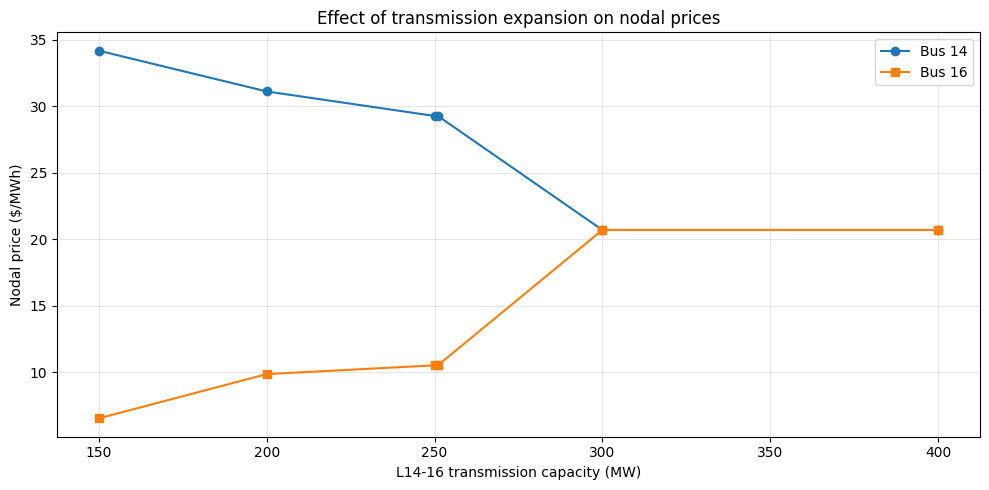

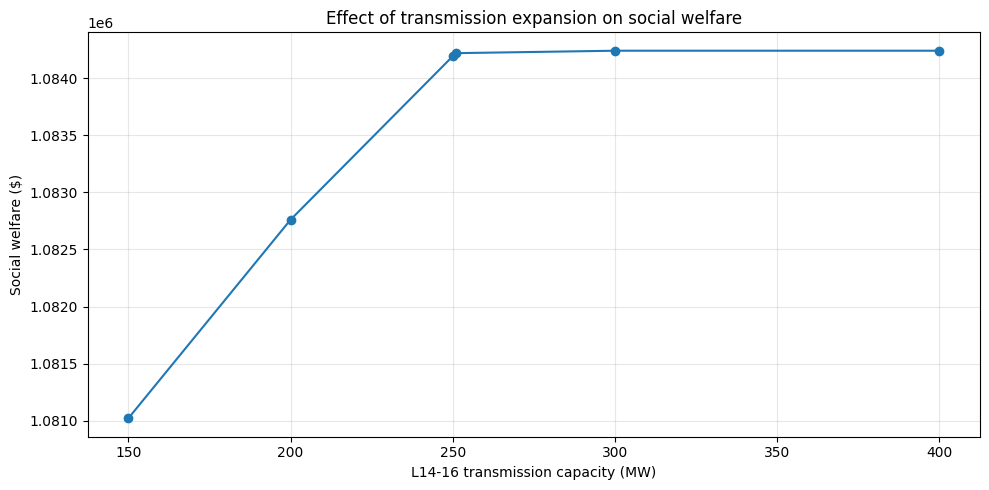

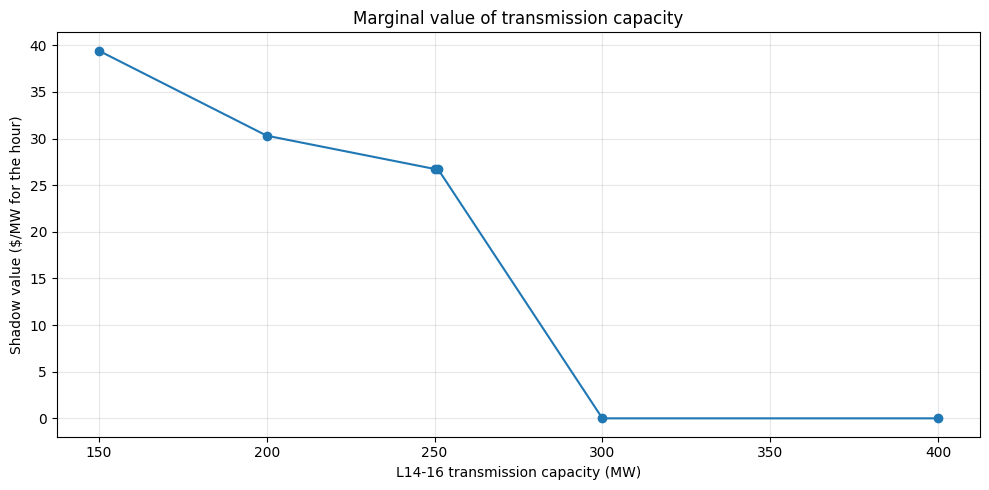

In [ ]:
df = sensitivity_df

plt.figure(figsize=(10, 5))

plt.plot(
    df.index, df["LMP_Bus14"],
    marker="o", label="Bus 14"
)

plt.plot(
    df.index, df["LMP_Bus16"],
    marker="s", label="Bus 16"
)

plt.xlabel("L14-16 transmission capacity (MW)")
plt.ylabel("Nodal price ($/MWh)")
plt.title("Effect of transmission expansion on nodal prices")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    df.index,
    df["Social_Welfare"],
    marker="o"
)

plt.xlabel("L14-16 transmission capacity (MW)")
plt.ylabel("Social welfare ($)")
plt.title("Effect of transmission expansion on social welfare")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    df.index,
    df["Line_Shadow_Value"],
    marker="o"
)

plt.xlabel("L14-16 transmission capacity (MW)")
plt.ylabel("Shadow value ($/MW for the hour)")
plt.title("Marginal value of transmission capacity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Step-3 (Zonal)

In [ ]:

# Create the zone mapping
zone_map = {
    bus: ("Zone_A" if bus <= 12 else "Zone_B")
    for bus in range(1, 25)
}

zonal_lines = line_data.copy()

zonal_lines["Zone_From"] = (
    zonal_lines["from_bus"].map(zone_map)
)

zonal_lines["Zone_To"] = (
    zonal_lines["to_bus"].map(zone_map)
)

# Lines crossing the zone boundary
interzonal_lines = zonal_lines[
    zonal_lines["Zone_From"] != zonal_lines["Zone_To"]
].copy()

print("Interzonal transmission lines:")
display(interzonal_lines[
    ["name", "from_bus", "to_bus", "capacity_mw"]
])

# Assignment's simplified ATC assumption:
# Sum the capacities of interzonal lines
ATC = interzonal_lines["capacity_mw"].sum()

print(f"\nIllustrative ATC: {ATC:.2f} MW")


Interzonal transmission lines:


,name,from_bus,to_bus,capacity_mw
6,L3-24,3,24,400
17,L11-13,11,13,500
18,L11-14,11,14,500
19,L12-13,12,13,500
20,L12-23,12,23,500



Illustrative ATC: 2400.00 MW


In [ ]:

def build_zonal_market(atc):

    z = pypsa.Network()
    z.set_snapshots(pd.Index(["Hour_1"], name="snapshot"))

    for carrier in ["conventional", "wind", "demand", "AC"]:
        z.add("Carrier", carrier)

    z.add("Bus", "Zone_A", carrier="AC")
    z.add("Bus", "Zone_B", carrier="AC")

    # Conventional generators
    for _, g in generators.iterrows():
        z.add(
            "Generator",
            g["name"],
            bus=zone_map[int(g["bus"])],
            p_nom=float(g["p_nom"]),
            marginal_cost=float(g["marginal_cost"]),
            carrier="conventional"
        )

    # Wind farms
    for _, w in wind_data.iterrows():
        z.add(
            "Generator",
            w["name"],
            bus=zone_map[int(w["bus"])],
            p_nom=float(w["p_nom"]),
            p_max_pu=float(w["availability"]),
            marginal_cost=0.0,
            carrier="wind"
        )

    # Price-elastic demands
    for _, d in load_data.iterrows():
        z.add(
            "Generator",
            f"D{int(d['bus'])}",
            bus=zone_map[int(d["bus"])],
            sign=-1,
            p_nom=float(d["demand_mw"]),
            marginal_cost=-float(d["bid_price"]),
            carrier="demand"
        )

    # Bidirectional interzonal transfer
    z.add(
        "Link",
        "Interzonal_Transfer",
        bus0="Zone_A",
        bus1="Zone_B",
        p_nom=float(atc),
        p_min_pu=-1.0,
        p_max_pu=1.0,
        efficiency=1.0,
        marginal_cost=0.0
    )

    return z


zonal = build_zonal_market(ATC)

status, condition = zonal.optimize(
    solver_name="highs",
    include_objective_constant=False
)

assert status == "ok" and condition == "optimal"

print("Zonal market cleared successfully.")


Zonal market cleared successfully.


In [ ]:

snapshot = zonal.snapshots[0]

zonal_prices = (
    zonal.buses_t.marginal_price.loc[snapshot]
)

zonal_dispatch = (
    zonal.generators_t.p.loc[snapshot]
)

metadata = zonal.generators

producers = metadata.index[
    metadata.carrier.isin(["conventional", "wind"])
]

consumers = metadata.index[
    metadata.carrier == "demand"
]

zonal_cost = (
    zonal_dispatch[producers]
    * metadata.loc[producers, "marginal_cost"]
).sum()

zonal_value = (
    zonal_dispatch[consumers]
    * -metadata.loc[consumers, "marginal_cost"]
).sum()

zonal_welfare = zonal_value - zonal_cost

transfer = zonal.links_t.p0.loc[
    snapshot, "Interzonal_Transfer"
]

print("Zonal electricity prices:")
display(zonal_prices)

print(f"\nInterzonal transfer: {transfer:.3f} MW")
print("Positive = Zone A to Zone B")

print(f"Production cost: ${zonal_cost:,.2f}")
print(f"Social welfare: ${zonal_welfare:,.2f}")

print("\nNodal welfare:",
      f"${nodal_welfare:,.2f}")

print("Zonal minus nodal welfare:",
      f"${zonal_welfare - nodal_welfare:,.2f}")

print("\nZonal generator dispatch:")
display(zonal_dispatch[producers].round(3))


Zonal electricity prices:


name
Zone_A    20.7
Zone_B    20.7
Name: Hour_1, dtype: float64


Interzonal transfer: -364.500 MW
Positive = Zone A to Zone B
Production cost: $19,260.57
Social welfare: $1,084,239.43

Nodal welfare: $1,084,191.31
Zonal minus nodal welfare: $48.11

Zonal generator dispatch:


name
G1     106.40
G2     106.40
G3     217.64
G4      -0.00
G5      -0.00
G6     108.50
G7     108.50
G8     280.00
G9     280.00
G10    210.00
G11    217.00
G12    245.00
W1     120.54
W2     115.52
W3      53.34
W4      38.16
Name: Hour_1, dtype: float64

In [ ]:

import numpy as np
import pandas as pd

# Zonal schedules from the previous optimization
snapshot = zonal.snapshots[0]
zonal_p = zonal.generators_t.p.loc[snapshot]

# Map each zonal generator and demand bid back to
# its original physical bus in the nodal network.
physical_meta = n_nodal.generators

bus_injections = pd.Series(
    0.0, index=range(1, 25), dtype=float
)

for name, dispatch_mw in zonal_p.items():
    bus_name = physical_meta.loc[name, "bus"]
    bus_number = int(bus_name.split("_")[1])
    sign = float(physical_meta.loc[name, "sign"])

    bus_injections.loc[bus_number] += sign * dispatch_mw

print("Total net injection (MW):", bus_injections.sum())
assert abs(bus_injections.sum()) < 1e-5

# Construct bus susceptance matrix
S_BASE = 100.0
B = np.zeros((24, 24))

for _, line in line_data.iterrows():
    i = int(line["from_bus"]) - 1
    j = int(line["to_bus"]) - 1

    b = S_BASE / float(line["x_pu"])

    B[i, i] += b
    B[j, j] += b
    B[i, j] -= b
    B[j, i] -= b

# Reference angle: Bus 13 = 0
slack = 12
non_slack = [i for i in range(24) if i != slack]

theta = np.zeros(24)

theta[non_slack] = np.linalg.solve(
    B[np.ix_(non_slack, non_slack)],
    bus_injections.to_numpy()[non_slack]
)

# Reconstruct power flows
physical_flows = []

for _, line in line_data.iterrows():
    i = int(line["from_bus"]) - 1
    j = int(line["to_bus"]) - 1

    flow = (
        S_BASE / float(line["x_pu"])
        * (theta[i] - theta[j])
    )

    capacity = float(line["capacity_mw"])

    physical_flows.append({
        "Line": line["name"],
        "Flow_MW": flow,
        "Capacity_MW": capacity,
        "Loading_pct": abs(flow) / capacity * 100,
        "Violation_MW": max(0, abs(flow) - capacity)
    })

physical_check = pd.DataFrame(
    physical_flows
).set_index("Line")

display(
    physical_check.sort_values(
        "Loading_pct", ascending=False
    ).round(4)
)

violations = physical_check[
    physical_check["Violation_MW"] > 1e-5
]

print("\nNumber of overloaded lines:", len(violations))
print("Total overload magnitude:",
      round(violations["Violation_MW"].sum(), 4), "MW")

print("\nOverloaded lines:")
display(violations.round(4))

print("\nL14-16 flow:",
      physical_check.loc["L14-16", "Flow_MW"], "MW")


Total net injection (MW): 1.1368683772161603e-13


,Flow_MW,Capacity_MW,Loading_pct,Violation_MW
Line,,,,
L14-16,-251.7989,250.0,100.7196,1.7989
L15-21,-321.2105,400.0,80.3026,0.0000
L13-23,-192.8769,250.0,77.1508,0.0000
L16-17,-228.9495,500.0,45.7899,0.0000
L3-9,68.8368,175.0,39.3353,0.0000
L6-10,-62.9895,175.0,35.9940,0.0000
L7-8,120.6400,350.0,34.4686,0.0000
L12-23,-163.0754,500.0,32.6151,0.0000
L3-24,-111.7488,400.0,27.9372,0.0000



Number of overloaded lines: 1
Total overload magnitude: 1.7989 MW

Overloaded lines:


,Flow_MW,Capacity_MW,Loading_pct,Violation_MW
Line,,,,
L14-16,-251.7989,250.0,100.7196,1.7989



L14-16 flow: -251.79889235603898 MW


In [ ]:

# Compare physical generation schedules
snapshot = n_nodal.snapshots[0]

producer_names = n_nodal.generators.index[
    n_nodal.generators.carrier.isin(
        ["conventional", "wind"]
    )
]

zonal_schedule = zonal.generators_t.p.loc[
    snapshot, producer_names
]

nodal_schedule = n_nodal.generators_t.p.loc[
    snapshot, producer_names
]

redispatch = pd.DataFrame({
    "Bus": n_nodal.generators.loc[
        producer_names, "bus"
    ],
    "Zonal_MW": zonal_schedule,
    "Nodal_MW": nodal_schedule,
    "Marginal_Cost": n_nodal.generators.loc[
        producer_names, "marginal_cost"
    ]
})

redispatch["Change_MW"] = (
    redispatch["Nodal_MW"]
    - redispatch["Zonal_MW"]
)

redispatch["Cost_Change_USD"] = (
    redispatch["Change_MW"]
    * redispatch["Marginal_Cost"]
)

# Upward and downward redispatch
upward = redispatch["Change_MW"].clip(lower=0).sum()
downward = (
    -redispatch["Change_MW"].clip(upper=0)
).sum()

print("Total upward redispatch:", round(upward, 4), "MW")
print("Total downward redispatch:", round(downward, 4), "MW")

print(
    "Net generation change:",
    round(redispatch["Change_MW"].sum(), 6),
    "MW"
)

print(
    "Net production-cost increase:",
    round(redispatch["Cost_Change_USD"].sum(), 4),
    "USD"
)

print("\nGenerators requiring adjustments:")
display(
    redispatch[
        redispatch["Change_MW"].abs() > 1e-5
    ].round(4)
)


Total upward redispatch: 4.7263 MW
Total downward redispatch: 4.7263 MW
Net generation change: -0.0 MW
Net production-cost increase: 48.1137 USD

Generators requiring adjustments:


,Bus,Zonal_MW,Nodal_MW,Marginal_Cost,Change_MW,Cost_Change_USD
name,,,,,,
G3,Bus_7,217.64,222.3663,20.70,4.7263,97.8343
G7,Bus_16,108.50,103.7737,10.52,-4.7263,-49.7206


In [ ]:

snapshot = n_nodal.snapshots[0]

producer_names = n_nodal.generators.index[
    n_nodal.generators.carrier.isin(
        ["conventional", "wind"]
    )
]

nodal_prices = n_nodal.buses_t.marginal_price.loc[snapshot]
zone_prices = zonal.buses_t.marginal_price.loc[snapshot]

records = []

for name in producer_names:
    bus = n_nodal.generators.loc[name, "bus"]
    bus_number = int(bus.split("_")[1])
    zone = zone_map[bus_number]

    cost = float(
        n_nodal.generators.loc[name, "marginal_cost"]
    )

    p_nodal = float(
        n_nodal.generators_t.p.loc[snapshot, name]
    )

    p_zonal = float(
        zonal.generators_t.p.loc[snapshot, name]
    )

    profit_nodal = (
        nodal_prices[bus] - cost
    ) * p_nodal

    profit_zonal = (
        zone_prices[zone] - cost
    ) * p_zonal

    records.append({
        "Generator": name,
        "Bus": bus,
        "Zone": zone,
        "Profit_Nodal": profit_nodal,
        "Profit_Zonal": profit_zonal,
        "Difference": profit_zonal - profit_nodal
    })

profit_comparison = pd.DataFrame(
    records
).set_index("Generator")

display(profit_comparison.round(3))

print("\nTotal nodal generator profit:",
      profit_comparison["Profit_Nodal"].sum())

print("Total zonal generator profit:",
      profit_comparison["Profit_Zonal"].sum())


,Bus,Zone,Profit_Nodal,Profit_Zonal,Difference
Generator,,,,,
G1,Bus_1,Zone_A,685.822,785.232,99.410
G2,Bus_2,Zone_A,695.795,785.232,89.437
G3,Bus_7,Zone_A,0.000,0.000,0.000
G4,Bus_13,Zone_B,0.000,0.000,0.000
G5,Bus_15,Zone_B,0.000,0.000,0.000
G6,Bus_15,Zone_B,63.002,1104.530,1041.528
G7,Bus_16,Zone_B,0.000,1104.530,1104.530
G8,Bus_18,Zone_B,1343.842,4110.400,2766.558
G9,Bus_21,Zone_B,1522.596,4264.400,2741.804



Total nodal generator profit: 12740.340072671546
Total zonal generator profit: 26424.326


In [ ]:

atc_values = [0, 100, 200, 300, 350, 400, 600, 1000, 2400]

atc_results = []
atc_networks = {}

for atc in atc_values:

    # Avoid a zero-capacity Link; represent zero ATC
    # with two isolated zones.
    z = build_zonal_market(max(float(atc), 1.0))

    z.links.loc["Interzonal_Transfer", "p_max_pu"] = (
        0.0 if atc == 0 else 1.0
    )
    z.links.loc["Interzonal_Transfer", "p_min_pu"] = (
        0.0 if atc == 0 else -1.0
    )

    status, condition = z.optimize(
        solver_name="highs",
        include_objective_constant=False
    )

    assert status == "ok" and condition == "optimal"

    snap = z.snapshots[0]
    prices = z.buses_t.marginal_price.loc[snap]
    p = z.generators_t.p.loc[snap]
    meta = z.generators

    producer_ids = meta.index[
        meta.carrier.isin(["conventional", "wind"])
    ]
    demand_ids = meta.index[
        meta.carrier == "demand"
    ]

    cost = (
        p[producer_ids]
        * meta.loc[producer_ids, "marginal_cost"]
    ).sum()

    value = (
        p[demand_ids]
        * -meta.loc[demand_ids, "marginal_cost"]
    ).sum()

    flow = z.links_t.p0.loc[
        snap, "Interzonal_Transfer"
    ]

    atc_results.append({
        "ATC_MW": atc,
        "Transfer_A_to_B_MW": flow,
        "Zone_A_Price": prices["Zone_A"],
        "Zone_B_Price": prices["Zone_B"],
        "Price_Spread": abs(
            prices["Zone_A"] - prices["Zone_B"]
        ),
        "Cleared_Demand_MW": p[demand_ids].sum(),
        "Production_Cost": cost,
        "Consumer_Value": value,
        "Social_Welfare": value - cost
    })

    atc_networks[atc] = z

atc_df = pd.DataFrame(atc_results).set_index("ATC_MW")

display(atc_df.round(3))


,Transfer_A_to_B_MW,Zone_A_Price,Zone_B_Price,Price_Spread,Cleared_Demand_MW,Production_Cost,Consumer_Value,Social_Welfare
ATC_MW,,,,,,,,
0,-0.0,500.0,10.52,489.48,1869.86,15901.736,934930.0,919028.264
100,-100.0,500.0,10.52,489.48,1969.86,16953.736,984930.0,967976.264
200,-200.0,500.0,10.89,489.11,2069.86,18035.521,1034930.0,1016894.479
300,-300.0,500.0,10.89,489.11,2169.86,19124.521,1084930.0,1065805.479
350,-350.0,20.7,10.89,9.81,2207.00,19402.819,1103500.0,1084097.181
400,-364.5,20.7,20.70,0.00,2207.00,19260.574,1103500.0,1084239.426
600,-364.5,20.7,20.70,0.00,2207.00,19260.574,1103500.0,1084239.426
1000,-364.5,20.7,20.70,0.00,2207.00,19260.574,1103500.0,1084239.426
2400,-364.5,20.7,20.70,0.00,2207.00,19260.574,1103500.0,1084239.426


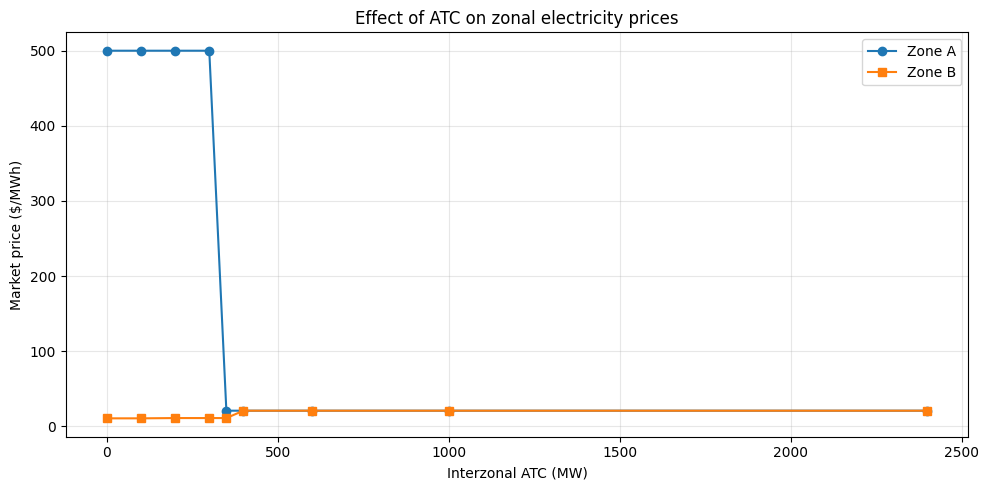

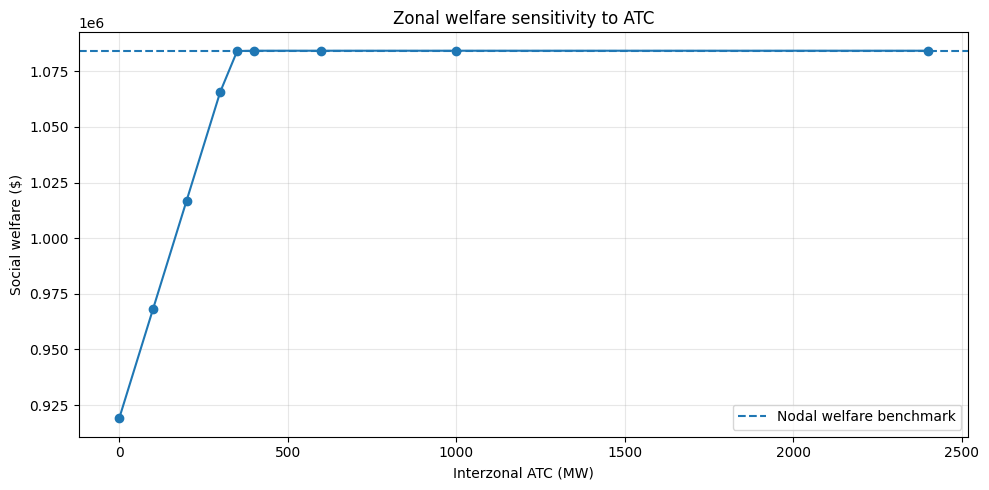

In [ ]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    atc_df.index,
    atc_df["Zone_A_Price"],
    marker="o",
    label="Zone A"
)

ax.plot(
    atc_df.index,
    atc_df["Zone_B_Price"],
    marker="s",
    label="Zone B"
)

ax.set_xlabel("Interzonal ATC (MW)")
ax.set_ylabel("Market price ($/MWh)")
ax.set_title("Effect of ATC on zonal electricity prices")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    atc_df.index,
    atc_df["Social_Welfare"],
    marker="o"
)

plt.axhline(
    nodal_welfare,
    linestyle="--",
    label="Nodal welfare benchmark"
)

plt.xlabel("Interzonal ATC (MW)")
plt.ylabel("Social welfare ($)")
plt.title("Zonal welfare sensitivity to ATC")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Step-5

In [ ]:
import numpy as np
import pandas as pd
import pypsa

# Rebuild and solve the Step 1 day-ahead market model to ensure results are populated
da_network = pypsa.Network()
da_network.set_snapshots(pd.Index(["Hour_1"], name="snapshot"))
da_network.add("Bus", "Market")

# Conventional generators
for _, g in generators.iterrows():
    da_network.add(
        "Generator",
        g["name"],
        bus="Market",
        p_nom=float(g["p_nom"]),
        marginal_cost=float(g["marginal_cost"]),
        carrier="conventional"
    )

# Wind farms
for _, w in wind_data.iterrows():
    da_network.add(
        "Generator",
        w["name"],
        bus="Market",
        p_nom=float(w["p_nom"]),
        p_max_pu=float(w["availability"]),
        marginal_cost=0.0,
        carrier="wind"
    )

# Price-elastic demand
for _, d in load_data.iterrows():
    da_network.add(
        "Generator",
        f"D{int(d['bus'])}",
        bus="Market",
        sign=-1,
        p_nom=float(d["demand_mw"]),
        marginal_cost=-float(d["bid_price"]),
        carrier="demand"
    )

status, condition = da_network.optimize(solver_name="highs", include_objective_constant=False)
assert status == "ok" and condition == "optimal"

print("Network buses:", da_network.buses.index.tolist())
print("Snapshots:", da_network.snapshots.tolist())

da_snapshot = da_network.snapshots[0]

# Extract generator and wind dispatch
da_dispatch = da_network.generators_t.p.loc[da_snapshot].copy()

# Copper-plate network should contain exactly one bus
assert len(da_network.buses) == 1, (
    "The selected network is not the single-bus "
    "Step 1 copper-plate model."
)

# Automatically retrieve the actual bus name
da_bus = da_network.buses.index[0]

da_price = float(
    da_network.buses_t.marginal_price.loc[
        da_snapshot, da_bus
    ]
)

# Verify expected Step 1 results
assert np.isclose(da_price, 20.70, atol=1e-4)
assert np.isclose(
    da_dispatch["G7"], 108.5, atol=1e-4
)

print("\nDay-ahead market price:",
      round(da_price, 3), "$/MWh")

print("G7 day-ahead dispatch:",
      round(da_dispatch["G7"], 3), "MW")

print("\nScheduled conventional generation:")
display(
    da_dispatch.loc[generators["name"]].round(3)
)

print("\nScheduled wind generation:")
display(
    da_dispatch.loc[wind_data["name"]].round(3)
)

Index(['Market'], dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')


Network buses: ['Market']
Snapshots: ['Hour_1']

Day-ahead market price: 20.7 $/MWh
G7 day-ahead dispatch: 108.5 MW

Scheduled conventional generation:


name
G1     106.40
G2     106.40
G3     217.64
G4      -0.00
G5      -0.00
G6     108.50
G7     108.50
G8     280.00
G9     280.00
G10    210.00
G11    217.00
G12    245.00
Name: Hour_1, dtype: float64


Scheduled wind generation:


name
W1    120.54
W2    115.52
W3     53.34
W4     38.16
Name: Hour_1, dtype: float64

In [ ]:

# Assignment-prescribed wind deviations
wind_deviations = {
    "W1": -0.15,
    "W2": -0.15,
    "W3":  0.10,
    "W4":  0.10
}

wind_actual = pd.DataFrame({
    "DA_MW": da_dispatch.loc[wind_data["name"]]
})

wind_actual["Deviation_pct"] = [
    wind_deviations[name] * 100
    for name in wind_actual.index
]

wind_actual["Actual_MW"] = (
    wind_actual["DA_MW"]
    * (1 + wind_actual["Deviation_pct"] / 100)
)

wind_actual["Imbalance_MW"] = (
    wind_actual["Actual_MW"] - wind_actual["DA_MW"]
)

outage_generator = "G7"
outage_mw = float(da_dispatch[outage_generator])

# Positive requirement means upward balancing is needed
wind_shortfall = -wind_actual["Imbalance_MW"].sum()

balancing_requirement = outage_mw + wind_shortfall

print("Wind results:")
display(wind_actual.round(3))

print(f"\nGenerator outage: {outage_mw:.3f} MW")
print(f"Wind shortfall: {wind_shortfall:.3f} MW")
print(
    f"Total balancing requirement: "
    f"{balancing_requirement:.3f} MW"
)

assert np.isclose(balancing_requirement, 134.759)


Wind results:


,DA_MW,Deviation_pct,Actual_MW,Imbalance_MW
name,,,,
W1,120.54,-15.0,102.459,-18.081
W2,115.52,-15.0,98.192,-17.328
W3,53.34,10.0,58.674,5.334
W4,38.16,10.0,41.976,3.816



Generator outage: 108.500 MW
Wind shortfall: 26.259 MW
Total balancing requirement: 134.759 MW


In [ ]:

flexible_units = [
    "G3", "G4", "G5", "G8",
    "G9", "G11", "G12"
]

offers = generators.set_index("name").loc[
    flexible_units
].copy()

offers["DA_MW"] = da_dispatch.loc[flexible_units]

offers["Headroom_MW"] = (
    offers["p_nom"] - offers["DA_MW"]
).clip(lower=0)

offers["Up_Max_MW"] = np.minimum(
    offers["reserve_up_max"],
    offers["Headroom_MW"]
)

offers["Down_Max_MW"] = np.minimum(
    offers["reserve_down_max"],
    offers["DA_MW"]
)

offers["Up_Offer"] = (
    da_price + 0.10 * offers["marginal_cost"]
)

offers["Down_Offer"] = (
    da_price - 0.15 * offers["marginal_cost"]
)

display(offers[[
    "DA_MW", "Headroom_MW",
    "Up_Max_MW", "Down_Max_MW",
    "Up_Offer", "Down_Offer"
]].round(3))

print(
    "Available upward regulation:",
    offers["Up_Max_MW"].sum(), "MW"
)


,DA_MW,Headroom_MW,Up_Max_MW,Down_Max_MW,Up_Offer,Down_Offer
name,,,,,,
G3,217.64,27.36,27.36,84.0,22.770,17.595
G4,-0.00,413.70,216.00,-0.0,22.793,17.560
G5,-0.00,42.00,42.00,-0.0,23.311,16.784
G8,280.00,0.00,0.00,60.0,21.302,19.797
G9,280.00,0.00,0.00,60.0,21.247,19.880
G11,217.00,0.00,0.00,72.0,21.752,19.122
G12,245.00,0.00,0.00,48.0,21.789,19.066


Available upward regulation: 285.3600000000001 MW


In [ ]:

bal = pypsa.Network()
bal.set_snapshots(pd.Index(["Balancing_Hour"], name="snapshot"))

for carrier in ["AC", "up_reg", "down_reg", "load_shedding"]:
    bal.add("Carrier", carrier)

bal.add("Bus", "Balancing_Bus", carrier="AC")

# The required net upward correction
bal.add(
    "Load",
    "System_Imbalance",
    bus="Balancing_Bus",
    p_set=float(balancing_requirement)
)

for name, g in offers.iterrows():

    # Upward balancing service
    if g["Up_Max_MW"] > 1e-7:
        bal.add(
            "Generator",
            f"UP_{name}",
            bus="Balancing_Bus",
            p_nom=float(g["Up_Max_MW"]),
            marginal_cost=float(g["Up_Offer"]),
            carrier="up_reg"
        )

    # Downward regulation represents reduction
    # in the original day-ahead generation schedule.
    if g["Down_Max_MW"] > 1e-7:
        bal.add(
            "Generator",
            f"DOWN_{name}",
            bus="Balancing_Bus",
            sign=-1,
            p_nom=float(g["Down_Max_MW"]),
            marginal_cost=-float(g["Down_Offer"]),
            carrier="down_reg"
        )

# Emergency replacement through load shedding
bal.add(
    "Generator",
    "LOAD_SHEDDING",
    bus="Balancing_Bus",
    p_nom=float(balancing_requirement),
    marginal_cost=500.0,
    carrier="load_shedding"
)

status, condition = bal.optimize(
    solver_name="highs",
    include_objective_constant=False
)

print("Solver status:", status)
print("Termination condition:", condition)

assert status == "ok" and condition == "optimal"


Solver status: ok
Termination condition: optimal


In [ ]:

snap = bal.snapshots[0]
bal_p = bal.generators_t.p.loc[snap]

balancing_price = float(
    bal.buses_t.marginal_price.loc[
        snap, "Balancing_Bus"
    ]
)

up = bal_p[
    bal.generators.carrier.eq("up_reg")
]

down = bal_p[
    bal.generators.carrier.eq("down_reg")
]

load_shedding = float(bal_p["LOAD_SHEDDING"])

total_up = up.sum()
total_down = down.sum()

up_cost = sum(
    bal_p[f"UP_{g}"] * offers.loc[g, "Up_Offer"]
    for g in flexible_units
    if f"UP_{g}" in bal_p.index
)

down_credit = sum(
    bal_p[f"DOWN_{g}"] * offers.loc[g, "Down_Offer"]
    for g in flexible_units
    if f"DOWN_{g}" in bal_p.index
)

net_balancing_cost = (
    up_cost - down_credit + 500.0 * load_shedding
)

print(f"Balancing price: ${balancing_price:.3f}/MWh")
print(f"Total upward regulation: {total_up:.3f} MW")
print(f"Total downward regulation: {total_down:.3f} MW")
print(f"Load shedding: {load_shedding:.3f} MW")
print(f"Net balancing cost: ${net_balancing_cost:,.2f}")

print("\nUpward regulation:")
display(up[up > 1e-6].round(4))

print("\nDownward regulation:")
display(down[down > 1e-6].round(4))

# Physical balancing validation
assert np.isclose(
    total_up - total_down + load_shedding,
    balancing_requirement,
    atol=1e-5
)

print("\nBalancing constraint satisfied.")


Balancing price: $22.793/MWh
Total upward regulation: 134.759 MW
Total downward regulation: 0.000 MW
Load shedding: -0.000 MW
Net balancing cost: $3,070.93

Upward regulation:


name
UP_G3     27.360
UP_G4    107.399
Name: Balancing_Hour, dtype: float64


Downward regulation:


Series([], Name: Balancing_Hour, dtype: float64)


Balancing constraint satisfied.


In [ ]:

# Actual production after outage, forecast errors,
# and activated balancing instructions

conventional_names = generators["name"].tolist()
wind_names = wind_data["name"].tolist()

actual_output = da_dispatch.loc[
    conventional_names + wind_names
].astype(float).copy()

# Apply outage
actual_output.loc["G7"] = 0.0

# Apply wind deviations
for name in wind_names:
    actual_output.loc[name] = float(
        wind_actual.loc[name, "Actual_MW"]
    )

# Apply instructed balancing regulation
for name in flexible_units:
    actual_output.loc[name] += float(
        bal_p.get(f"UP_{name}", 0.0)
    )
    actual_output.loc[name] -= float(
        bal_p.get(f"DOWN_{name}", 0.0)
    )

output_check = pd.DataFrame({
    "Day_Ahead_MW": da_dispatch.loc[
        conventional_names + wind_names
    ],
    "Actual_MW": actual_output
})

output_check["Difference_MW"] = (
    output_check["Actual_MW"]
    - output_check["Day_Ahead_MW"]
)

display(output_check.round(3))

print("Total actual generation:",
      round(actual_output.sum(), 4), "MW")

assert np.isclose(
    actual_output.sum() + load_shedding,
    2207.0,
    atol=1e-4
)

print("Real-time energy balance satisfied.")


,Day_Ahead_MW,Actual_MW,Difference_MW
name,,,
G1,106.40,106.400,0.000
G2,106.40,106.400,0.000
G3,217.64,245.000,27.360
G4,-0.00,107.399,107.399
G5,-0.00,-0.000,0.000
G6,108.50,108.500,0.000
G7,108.50,0.000,-108.500
G8,280.00,280.000,0.000
G9,280.00,280.000,0.000


Total actual generation: 2207.0 MW
Real-time energy balance satisfied.


In [ ]:

unit_costs = pd.concat([
    generators.set_index("name")["marginal_cost"],
    pd.Series(0.0, index=wind_names)
])

settlement_records = []

for name in conventional_names + wind_names:

    scheduled = float(da_dispatch[name])
    actual = float(actual_output[name])
    cost = float(unit_costs[name])

    # Instructed regulation
    upward = float(bal_p.get(f"UP_{name}", 0.0))
    downward = float(bal_p.get(f"DOWN_{name}", 0.0))

    instructed_change = upward - downward

    # Remaining deviation is uninstructed
    passive_imbalance = (
        actual - scheduled - instructed_change
    )

    # Day-ahead settlement
    da_revenue = da_price * scheduled

    # Instructed regulation payment
    regulation_revenue = (
        balancing_price * instructed_change
    )

    # One-price: every passive deviation at balancing price
    one_price_imbalance_revenue = (
        balancing_price * passive_imbalance
    )

    # Two-price: system short, positive deviation helps
    if passive_imbalance >= 0:
        two_price_imbalance_revenue = (
            da_price * passive_imbalance
        )
    else:
        two_price_imbalance_revenue = (
            balancing_price * passive_imbalance
        )

    production_cost = actual * cost

    profit_one = (
        da_revenue
        + regulation_revenue
        + one_price_imbalance_revenue
        - production_cost
    )

    profit_two = (
        da_revenue
        + regulation_revenue
        + two_price_imbalance_revenue
        - production_cost
    )

    settlement_records.append({
        "Unit": name,
        "DA_MW": scheduled,
        "Actual_MW": actual,
        "Instructed_MW": instructed_change,
        "Passive_Imbalance_MW": passive_imbalance,
        "DA_Revenue": da_revenue,
        "Regulation_Revenue": regulation_revenue,
        "Profit_One_Price": profit_one,
        "Profit_Two_Price": profit_two,
        "Profit_Difference": profit_one - profit_two
    })

settlement_df = pd.DataFrame(
    settlement_records
).set_index("Unit")

display(settlement_df.round(3))

print("\nTotal generator and wind profits:")
print(
    "One-price:",
    round(settlement_df["Profit_One_Price"].sum(), 3)
)
print(
    "Two-price:",
    round(settlement_df["Profit_Two_Price"].sum(), 3)
)

print("\nWind-farm settlement comparison:")
display(
    settlement_df.loc[wind_names, [
        "Passive_Imbalance_MW",
        "Profit_One_Price",
        "Profit_Two_Price",
        "Profit_Difference"
    ]].round(3)
)


,DA_MW,Actual_MW,Instructed_MW,Passive_Imbalance_MW,DA_Revenue,Regulation_Revenue,Profit_One_Price,Profit_Two_Price,Profit_Difference
Unit,,,,,,,,,
G1,106.40,106.400,0.000,0.000,2202.480,0.000,785.232,785.232,0.000
G2,106.40,106.400,0.000,0.000,2202.480,0.000,785.232,785.232,0.000
G3,217.64,245.000,27.360,0.000,4505.148,623.616,57.264,57.264,0.000
G4,-0.00,107.399,107.399,0.000,-0.000,2447.945,200.084,200.084,0.000
G5,-0.00,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,0.000
G6,108.50,108.500,0.000,0.000,2245.950,0.000,1104.530,1104.530,0.000
G7,108.50,0.000,0.000,-108.500,2245.950,0.000,-227.091,-227.091,0.000
G8,280.00,280.000,0.000,0.000,5796.000,0.000,4110.400,4110.400,0.000
G9,280.00,280.000,0.000,0.000,5796.000,0.000,4264.400,4264.400,0.000



Total generator and wind profits:
One-price: 24751.533
Two-price: 24732.382

Wind-farm settlement comparison:


,Passive_Imbalance_MW,Profit_One_Price,Profit_Two_Price,Profit_Difference
Unit,,,,
W1,-18.081,2083.058,2083.058,0.000
W2,-17.328,1996.307,1996.307,0.000
W3,5.334,1225.716,1214.552,11.164
W4,3.816,876.890,868.903,7.987


In [ ]:

positive_wind_deviations = (
    wind_actual["Imbalance_MW"]
    .clip(lower=0)
    .sum()
)

expected_difference = (
    positive_wind_deviations
    * (balancing_price - da_price)
)

observed_difference = (
    settlement_df["Profit_One_Price"].sum()
    - settlement_df["Profit_Two_Price"].sum()
)

print("Positive wind deviation:",
      positive_wind_deviations, "MWh")

print("Expected settlement difference:",
      round(expected_difference, 4), "USD")

print("Observed settlement difference:",
      round(observed_difference, 4), "USD")

assert np.isclose(
    expected_difference,
    observed_difference,
    atol=1e-5
)

print("\nSettlement comparison validated.")


Positive wind deviation: 9.150000000000006 MWh
Expected settlement difference: 19.151 USD
Observed settlement difference: 19.1509 USD

Settlement comparison validated.


Step-6

In [ ]:

import numpy as np
import pandas as pd
from scipy.optimize import linprog

# Same seven flexible units as Step 5
flexible_units = [
    "G3", "G4", "G5", "G8",
    "G9", "G11", "G12"
]

reserve_data = pd.DataFrame({
    "Unit": flexible_units,
    "Up_Cost":   [3.30, 4.07, 1.89, 4.98, 5.53, 3.45, 5.11],
    "Down_Cost": [4.67, 3.93, 3.11, 5.02, 4.97, 2.52, 2.89],
    "Up_Max":    [84, 216, 42, 60, 60, 72, 48],
    "Down_Max":  [84, 216, 42, 60, 60, 72, 48]
}).set_index("Unit")

# Retrieve generator nameplate capacities
reserve_data["P_Max"] = (
    generators.set_index("name")
    .loc[flexible_units, "p_nom"]
    .astype(float)
)

total_demand = float(load_data["demand_mw"].sum())

reserve_up_required = 0.15 * total_demand
reserve_down_required = 0.10 * total_demand

print(f"Total demand: {total_demand:.2f} MW")
print(f"Upward reserve requirement: {reserve_up_required:.2f} MW")
print(f"Downward reserve requirement: {reserve_down_required:.2f} MW")

display(reserve_data)


Total demand: 2207.00 MW
Upward reserve requirement: 331.05 MW
Downward reserve requirement: 220.70 MW


,Up_Cost,Down_Cost,Up_Max,Down_Max,P_Max
Unit,,,,,
G3,3.30,4.67,84,84,245.0
G4,4.07,3.93,216,216,413.7
G5,1.89,3.11,42,42,42.0
G8,4.98,5.02,60,60,280.0
G9,5.53,4.97,60,60,280.0
G11,3.45,2.52,72,72,217.0
G12,5.11,2.89,48,48,245.0


In [ ]:

N = len(flexible_units)

# Objective: total procurement cost
c = np.concatenate([
    reserve_data["Up_Cost"].to_numpy(),
    reserve_data["Down_Cost"].to_numpy()
])

A_ub = []
b_ub = []

# Minimum upward reserve procurement
row_up = np.zeros(2 * N)
row_up[:N] = -1.0

A_ub.append(row_up)
b_ub.append(-reserve_up_required)

# Minimum downward reserve procurement
row_down = np.zeros(2 * N)
row_down[N:] = -1.0

A_ub.append(row_down)
b_ub.append(-reserve_down_required)

# Coupling: RU_g + RD_g <= Pmax_g
for i, unit in enumerate(flexible_units):

    row = np.zeros(2 * N)
    row[i] = 1.0
    row[N + i] = 1.0

    A_ub.append(row)
    b_ub.append(reserve_data.loc[unit, "P_Max"])

# Individual technical reserve-capability limits
bounds = (
    [(0, x) for x in reserve_data["Up_Max"]]
    +
    [(0, x) for x in reserve_data["Down_Max"]]
)

reserve_result = linprog(
    c=c,
    A_ub=np.array(A_ub),
    b_ub=np.array(b_ub),
    bounds=bounds,
    method="highs"
)

assert reserve_result.success, reserve_result.message

reserve_awards = reserve_data.copy()

reserve_awards["RU_Award_MW"] = reserve_result.x[:N]
reserve_awards["RD_Award_MW"] = reserve_result.x[N:]

reserve_awards["Award_Cost"] = (
    reserve_awards["RU_Award_MW"]
    * reserve_awards["Up_Cost"]
    +
    reserve_awards["RD_Award_MW"]
    * reserve_awards["Down_Cost"]
)

print("Reserve market cleared successfully.")

display(reserve_awards[[
    "P_Max",
    "RU_Award_MW",
    "RD_Award_MW",
    "Award_Cost"
]].round(4))

print("\nTotal upward reserve procured:",
      round(reserve_awards["RU_Award_MW"].sum(), 4), "MW")

print("Total downward reserve procured:",
      round(reserve_awards["RD_Award_MW"].sum(), 4), "MW")

print("Total reserve procurement offer cost:",
      round(reserve_result.fun, 4), "USD")

# Marginal prices of the two reserve requirements
# scipy/HiGHS reports inequality marginals for A_ub x <= b_ub;
# our requirements were written with negative signs.
up_reserve_price = -reserve_result.ineqlin.marginals[0]
down_reserve_price = -reserve_result.ineqlin.marginals[1]

print("\nUpward reserve market-clearing price:",
      round(up_reserve_price, 4), "$/MW")

print("Downward reserve market-clearing price:",
      round(down_reserve_price, 4), "$/MW")


Reserve market cleared successfully.


,P_Max,RU_Award_MW,RD_Award_MW,Award_Cost
Unit,,,,
G3,245.0,84.00,0.0,277.2000
G4,413.7,133.05,100.7,937.2645
G5,42.0,42.00,-0.0,79.3800
G8,280.0,0.00,0.0,0.0000
G9,280.0,0.00,0.0,0.0000
G11,217.0,72.00,72.0,429.8400
G12,245.0,0.00,48.0,138.7200



Total upward reserve procured: 331.05 MW
Total downward reserve procured: 220.7 MW
Total reserve procurement offer cost: 1862.4045 USD

Upward reserve market-clearing price: 4.07 $/MW
Downward reserve market-clearing price: 3.93 $/MW


In [ ]:

awards = reserve_awards.copy()

awards["Min_DA_Output"] = awards["RD_Award_MW"]

awards["Max_DA_Output"] = (
    awards["P_Max"] - awards["RU_Award_MW"]
)

awards["DA_Feasible_Range_MW"] = (
    awards["Max_DA_Output"]
    - awards["Min_DA_Output"]
)

assert (
    awards["RU_Award_MW"]
    <= awards["Up_Max"] + 1e-6
).all()

assert (
    awards["RD_Award_MW"]
    <= awards["Down_Max"] + 1e-6
).all()

assert (
    awards["Min_DA_Output"]
    <= awards["Max_DA_Output"] + 1e-6
).all()

assert np.isclose(
    awards["RU_Award_MW"].sum(),
    reserve_up_required,
    atol=1e-5
)

assert np.isclose(
    awards["RD_Award_MW"].sum(),
    reserve_down_required,
    atol=1e-5
)

print("Reserve requirements and generator limits validated.")

print("\nDay-ahead operating ranges after reserve procurement:")
display(awards[[
    "Min_DA_Output",
    "Max_DA_Output",
    "DA_Feasible_Range_MW"
]].round(4))


Reserve requirements and generator limits validated.

Day-ahead operating ranges after reserve procurement:


,Min_DA_Output,Max_DA_Output,DA_Feasible_Range_MW
Unit,,,
G3,0.0,161.00,161.00
G4,100.7,280.65,179.95
G5,-0.0,0.00,0.00
G8,0.0,280.00,280.00
G9,0.0,280.00,280.00
G11,72.0,145.00,73.00
G12,48.0,245.00,197.00


In [ ]:

import numpy as np
import pandas as pd
import pypsa

# Original Step 1 copper-plate network
da_baseline = n

assert len(da_baseline.buses) == 1, (
    "Expected the original single-bus Step 1 network."
)

# Create an independent network for sequential clearing
da_after_reserve = da_baseline.copy()

# Apply reserve-constrained generation limits
for name in flexible_units:

    p_nom = float(
        da_after_reserve.generators.loc[name, "p_nom"]
    )

    ru = float(
        reserve_awards.loc[name, "RU_Award_MW"]
    )

    rd = float(
        reserve_awards.loc[name, "RD_Award_MW"]
    )

    # New feasible operating range:
    # RD <= P_DA <= Pmax - RU
    da_after_reserve.generators.loc[
        name, "p_min_pu"
    ] = rd / p_nom

    da_after_reserve.generators.loc[
        name, "p_max_pu"
    ] = (p_nom - ru) / p_nom

# Solve the new day-ahead market
status, condition = da_after_reserve.optimize(
    solver_name="highs",
    include_objective_constant=False
)

assert status == "ok" and condition == "optimal"

print("Day-ahead market cleared after reserve procurement.")


Index(['Market'], dtype='object', name='name')
Index(['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10', 'G11',
       'G12', 'W1', 'W2', 'W3', 'W4', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7',
       'D8', 'D9', 'D10', 'D13', 'D14', 'D15', 'D16', 'D18', 'D19', 'D20'],
      dtype='object', name='name')


Day-ahead market cleared after reserve procurement.


In [ ]:
base_snap = da_network.snapshots[0]
new_snap = da_after_reserve.snapshots[0]

base_bus = da_network.buses.index[0]
new_bus = da_after_reserve.buses.index[0]

price_original = float(
    da_network.buses_t.marginal_price.loc[
        base_snap, base_bus
    ]
)

price_after = float(
    da_after_reserve.buses_t.marginal_price.loc[
        new_snap, new_bus
    ]
)

producer_names = (
    generators["name"].tolist()
    + wind_data["name"].tolist()
)

p_original = da_network.generators_t.p.loc[
    base_snap, producer_names
]

p_after = da_after_reserve.generators_t.p.loc[
    new_snap, producer_names
]

schedule_comparison = pd.DataFrame({
    "Original_MW": p_original,
    "After_Reserve_MW": p_after
})

schedule_comparison["Change_MW"] = (
    schedule_comparison["After_Reserve_MW"]
    - schedule_comparison["Original_MW"]
)

print("Original day-ahead price:", price_original)
print("After reserve procurement:", price_after)

print("\nGenerator dispatch comparison:")
display(schedule_comparison.round(4))

print("\nChanged generator schedules:")
display(
    schedule_comparison[
        schedule_comparison["Change_MW"].abs() > 1e-6
    ].round(4)
)

print("\nTotal dispatch change:",
      schedule_comparison["Change_MW"].sum(), "MW")

Original day-ahead price: 20.7
After reserve procurement: 20.93

Generator dispatch comparison:


,Original_MW,After_Reserve_MW,Change_MW
name,,,
G1,106.40,106.40,0.00
G2,106.40,106.40,0.00
G3,217.64,161.00,-56.64
G4,-0.00,128.64,128.64
G5,-0.00,-0.00,0.00
G6,108.50,108.50,0.00
G7,108.50,108.50,0.00
G8,280.00,280.00,0.00
G9,280.00,280.00,0.00



Changed generator schedules:


,Original_MW,After_Reserve_MW,Change_MW
name,,,
G3,217.64,161.00,-56.64
G4,-0.00,128.64,128.64
G11,217.00,145.00,-72.00



Total dispatch change: 0.0 MW


In [ ]:
# Use Table F.4's marginal production costs
generator_costs = (
    generators.set_index("name")["marginal_cost"]
)

cost_original = (
    p_original.loc[generator_costs.index]
    * generator_costs
).sum()

cost_after = (
    p_after.loc[generator_costs.index]
    * generator_costs
).sum()

# Both cases use the same demand bids and forecast
# Use the clean da_network instead of the overwritten da_baseline
demand_names = da_network.generators.index[
    da_network.generators["sign"] == -1
]

def consumer_value(network, snapshot):
    demand_p = network.generators_t.p.loc[
        snapshot, demand_names
    ]
    bids = -network.generators.loc[
        demand_names, "marginal_cost"
    ]
    return float((demand_p * bids).sum())

value_original = consumer_value(
    da_network, base_snap
)

value_after = consumer_value(
    da_after_reserve, new_snap
)

welfare_original = value_original - cost_original
welfare_after = value_after - cost_after

economic_comparison = pd.DataFrame({
    "Original_DA": [
        price_original,
        cost_original,
        value_original,
        welfare_original
    ],
    "After_Reserve": [
        price_after,
        cost_after,
        value_after,
        welfare_after
    ]
}, index=[
    "Electricity_Price",
    "Production_Cost",
    "Consumer_Value",
    "Social_Welfare"
])

economic_comparison["Change"] = (
    economic_comparison["After_Reserve"]
    - economic_comparison["Original_DA"]
)

display(economic_comparison.round(4))

# Verify the new generation schedule respects reserve awards
for name in flexible_units:
    p = float(p_after[name])

    lower = float(
        reserve_awards.loc[name, "RD_Award_MW"]
    )

    upper = float(
        reserve_awards.loc[name, "P_Max"]
        - reserve_awards.loc[name, "RU_Award_MW"]
    )

    assert lower - 1e-5 <= p <= upper + 1e-5, name

print("\nAll reserve-constrained generator limits satisfied.")

,Original_DA,After_Reserve,Change
Electricity_Price,20.700,2.093000e+01,0.2300
Production_Cost,19260.574,2.002312e+04,762.5472
Consumer_Value,1103500.000,1.103500e+06,0.0000
Social_Welfare,1084239.426,1.083477e+06,-762.5472



All reserve-constrained generator limits satisfied.


Optional

In [ ]:

from scipy.optimize import linprog
import numpy as np
import pandas as pd

# Original one-hour energy-market network
base = da_baseline
snap = base.snapshots[0]

energy_names = base.generators.index.tolist()
M = len(energy_names)
N = len(flexible_units)

# Decision vector:
# [energy dispatch for all units, RU for flexible units,
#  RD for flexible units]

energy_costs = base.generators.loc[
    energy_names, "marginal_cost"
].astype(float).to_numpy()

joint_c = np.concatenate([
    energy_costs,
    reserve_data.loc[flexible_units, "Up_Cost"].to_numpy(),
    reserve_data.loc[flexible_units, "Down_Cost"].to_numpy()
])

# Obtain each unit's actual Step 1 operating bounds
energy_bounds = []

for name in energy_names:
    row = base.generators.loc[name]

    p_nom = float(row["p_nom"])

    pmin = float(row["p_min_pu"])
    pmax = float(row["p_max_pu"])

    if (
        not base.generators_t.p_max_pu.empty
        and name in base.generators_t.p_max_pu.columns
    ):
        pmax = float(
            base.generators_t.p_max_pu.loc[snap, name]
        )

    if (
        not base.generators_t.p_min_pu.empty
        and name in base.generators_t.p_min_pu.columns
    ):
        pmin = float(
            base.generators_t.p_min_pu.loc[snap, name]
        )

    energy_bounds.append((
        max(0.0, p_nom * pmin),
        p_nom * pmax
    ))

joint_bounds = (
    energy_bounds
    + [(0, float(x)) for x in reserve_data.loc[
        flexible_units, "Up_Max"
    ]]
    + [(0, float(x)) for x in reserve_data.loc[
        flexible_units, "Down_Max"
    ]]
)

num_vars = M + 2 * N

# Power balance: demand - generation = 0
A_eq = np.zeros((1, num_vars))

A_eq[0, :M] = -base.generators.loc[
    energy_names, "sign"
].astype(float).to_numpy()

b_eq = np.array([0.0])

A_ub = []
b_ub = []

# Upward reserve requirement
row = np.zeros(num_vars)
row[M:M + N] = -1.0
A_ub.append(row)
b_ub.append(-reserve_up_required)

# Downward reserve requirement
row = np.zeros(num_vars)
row[M + N:M + 2*N] = -1.0
A_ub.append(row)
b_ub.append(-reserve_down_required)

for i, name in enumerate(flexible_units):
    j = energy_names.index(name)
    p_nom = float(base.generators.loc[name, "p_nom"])

    # Energy + upward reserve <= nameplate capacity
    row_up = np.zeros(num_vars)
    row_up[j] = 1.0
    row_up[M + i] = 1.0

    A_ub.append(row_up)
    b_ub.append(p_nom)

    # Downward reserve <= scheduled energy
    row_down = np.zeros(num_vars)
    row_down[j] = -1.0
    row_down[M + N + i] = 1.0

    A_ub.append(row_down)
    b_ub.append(0.0)

joint_result = linprog(
    c=joint_c,
    A_eq=A_eq,
    b_eq=b_eq,
    A_ub=np.array(A_ub),
    b_ub=np.array(b_ub),
    bounds=joint_bounds,
    method="highs"
)

assert joint_result.success, joint_result.message

joint_energy = pd.Series(
    joint_result.x[:M],
    index=energy_names
)

joint_ru = pd.Series(
    joint_result.x[M:M + N],
    index=flexible_units
)

joint_rd = pd.Series(
    joint_result.x[M + N:],
    index=flexible_units
)

# Dual prices from the joint optimization
joint_energy_price = float(
    joint_result.eqlin.marginals[0]
)

joint_ru_price = float(
    -joint_result.ineqlin.marginals[0]
)

joint_rd_price = float(
    -joint_result.ineqlin.marginals[1]
)

print("JOINT MARKET CLEARED")
print("Electricity price:", round(joint_energy_price, 4))
print("Upward reserve price:", round(joint_ru_price, 4))
print("Downward reserve price:", round(joint_rd_price, 4))

joint_schedule = pd.DataFrame({
    "Energy_MW": joint_energy.reindex(
        flexible_units
    ),
    "RU_MW": joint_ru,
    "RD_MW": joint_rd
})

display(joint_schedule.round(4))


JOINT MARKET CLEARED
Electricity price: -20.7
Upward reserve price: 4.07
Downward reserve price: 4.16


,Energy_MW,RU_MW,RD_MW
G3,116.94,84.00,0.0
G4,100.70,205.05,100.7
G5,0.00,42.00,-0.0
G8,280.00,0.00,0.0
G9,280.00,0.00,0.0
G11,217.00,-0.00,72.0
G12,245.00,0.00,48.0


In [ ]:

# Cell 54 — Correct dual sign and finalize Step 6

joint_energy_price = float(
    -joint_result.eqlin.marginals[0]
)

comparison.loc[
    "Electricity_Price", "Joint"
] = joint_energy_price

comparison["Joint_Minus_Sequential"] = (
    comparison["Joint"]
    - comparison["Sequential"]
)

# Check joint generation/demand balance
unit_signs = base.generators.loc[
    energy_names, "sign"
].astype(float)

net_injection = float(
    (joint_energy * unit_signs).sum()
)

assert np.isclose(net_injection, 0.0, atol=1e-5)

assert np.isclose(
    joint_energy_price, 20.70, atol=1e-5
)

assert np.isclose(
    joint_ru.sum(), reserve_up_required, atol=1e-5
)

assert np.isclose(
    joint_rd.sum(), reserve_down_required, atol=1e-5
)

display(comparison.round(4))

print(
    "Combined cost saving:",
    round(sequential_total_cost - joint_total_cost, 4),
    "USD"
)

print("Energy balance and reserve requirements validated.")


,Sequential,Joint,Joint_Minus_Sequential
Electricity_Price,20.9300,20.7000,-0.2300
Upward_Reserve_Price,4.0700,4.0700,0.0000
Downward_Reserve_Price,3.9300,4.1600,0.2300
Energy_Production_Cost,20023.1212,19283.7350,-739.3862
Reserve_Offer_Cost,1862.4045,1907.0445,44.6400
Combined_Cost,21885.5257,21190.7795,-694.7462


Combined cost saving: 694.7462 USD
Energy balance and reserve requirements validated.
